# Antigen expression, ALRA imputation and antigen-pair co-expression


ROR1 transcript detection is characterised, ALRA imputation is run per sample
for visualisation, the two antigen pairs are called on raw counts at a single
shared threshold, and their prevalence is related to clinical condition and
epithelial programme class.


## Setup

In [1]:
from scipy.special import gammaln
from itertools import combinations
from math import comb
import gc
import os
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import scanpy as sc

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns

from scipy.stats import binomtest, mannwhitneyu, wilcoxon
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests

import rpy2.robjects as ro
import rpy2.rinterface_lib.callbacks as rcb
from rpy2.robjects import numpy2ri
from rpy2.robjects.conversion import localconverter
import logging



Error importing in API mode: ImportError("dlopen(/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: @rpath/R/lib/libR.dylib\n  Referenced from: <CBEF4F67-1D94-3EA0-88C4-F34EBE0600C2> /Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/bin/../lib/R/lib/libR.dylib' (no such file), '/Users/g

In [2]:
np.random.seed(0)

In [3]:
sc.settings.verbosity = 1

In [4]:
rcb.logger.setLevel(logging.ERROR)

In [5]:
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")

In [6]:
plt.rcParams.update({
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 16,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
})

In [7]:
# genes and groupings used throughout
target_genes = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]

In [8]:
antigen_pairs = [("ROR1", "EGFR"), ("EPCAM", "ERBB2")]

In [9]:
conditions = ["N", "ER+", "HER2+", "TN"]

In [10]:
tumour_conditions = ["TN", "HER2+", "ER+"]

In [11]:
# a cell is positive for a gene at this raw UMI count. Both pairs use the same threshold so their prevalences are on one scale. Only filtered count matrices exist for GSE161529, so ambient RNA cannot be removed and the sweep below reports every panel at 1, 2 and 3 UMI.
primary_min_umi = 1

min_umi_sweep = [1, 2, 3]

ror1_alra_positive_threshold = 0.1  #spatial cutoff already used for "ALRA-positive" in the imputation panels

In [12]:
# paths; set CAP_PROJECT to run this outside the author's machine
#project  = Path(os.environ.get("CAP_PROJECT","~/Downloads/1105_Project_Nowotny")).expanduser()#4 Helena
project  = Path(os.environ.get("CAP_PROJECT", "/Volumes/TOSHIBA EXT/IdeaProjects/Nowotny")).expanduser()#4 Nina

In [13]:
fig_dir = project / "Figures"

In [14]:
df_dir = project / "Dataframe_Saves"

In [15]:
save_dir = project / "Adata_Saves"

In [16]:
metadata_dir = project / "metadata"

In [17]:
for d in [fig_dir, df_dir, save_dir]:
    d.mkdir(parents=True, exist_ok=True)

In [18]:
sc.settings.figdir = fig_dir

# show paths relative to the project root, so no absolute path is ever printed
def rel(path):
    return Path(path).relative_to(project)

## Load

In [19]:
epi = sc.read_h5ad(save_dir / "epithelial_gavish.h5ad")

In [20]:
epi

AnnData object with n_obs × n_vars = 119673 × 27274
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'sample_short', 'celltypist_pal_label', 'celltypist_pal_conf', 'cl_annotation', 'cnv_score', 'cnv_signal', 'cnv_high_screen', 'malignant', 'malignancy_review_pending', 'malignancy_status', 'leiden_r0.2', 'leiden_r0.4', 'leiden_r0.6', 'leiden_r0.8', 'leiden_r1', 'leiden_r1.2', 'leiden_r1.5', 'leiden_r2', 'epi_leiden', 'cnv_forced_nonmalignant', 'cnv_signature_score', 'cnv_signature_support', 'malignancy_label', 'malignant_status', 'Gavish_MP1', 'Gavish_MP2', 'Gavish_MP3', 'Gavish_MP4', 'Gavish_MP5', 'Gavish_MP6', 'Gavis

In [21]:
epi.obs["condition"].value_counts()

condition
ER+      57852
N        25682
TN       19615
HER2+    16524
Name: count, dtype: int64

In [22]:
for gene in target_genes:
    assert gene in epi.var_names, gene

In [23]:
for layer in ["counts", "lognorm"]:
    assert layer in epi.layers, layer

In [24]:
# raw positive-cell counts, re-checked after ALRA
baseline_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}

In [25]:
baseline_positive

{'ROR1': 983, 'ROR2': 2622, 'EGFR': 11183, 'ERBB2': 35406, 'EPCAM': 57376}

In [26]:
def raw_counts(adata, gene):
    # raw UMI counts for one gene as a dense 1d array
    values = adata[:, gene].layers["counts"]
    return np.asarray(values.todense()).ravel() if sp.issparse(values) else np.asarray(values).ravel()

## ROR1 transcript detection



ROR1 is compared with genes of the same class and with positive controls, to
show that its sparsity is a property of the transcript rather than of the
dataset.

In [27]:
comparison_genes = {
    "ROR1": "target gene, surface receptor",
    "EPCAM": "epithelial marker",
    "MKI67": "proliferation marker",
    "ACTB": "housekeeping gene",
    "EGFR": "surface receptor",
    "ERBB2": "surface receptor",
}

In [28]:
comparison_genes = {g: d for g, d in comparison_genes.items() if g in epi.var_names}

In [29]:
detection = {g: raw_counts(epi, g) for g in comparison_genes}

In [30]:
rows = []

In [31]:
for gene, values in detection.items():
    rows.append({
        "gene": gene,
        "description": comparison_genes[gene],
        "pct_zero": 100 * (values == 0).mean(),
        "pct_detected": 100 * (values > 0).mean(),
        "pct_count1": 100 * (values == 1).mean(),
        "pct_count2plus": 100 * (values >= 2).mean(),
        "mean_count": values.mean(),
        "max_count": int(values.max()),
    })

In [32]:
detection_stats = pd.DataFrame(rows).set_index("gene")

In [33]:
detection_stats.round(3)

,description,pct_zero,pct_detected,pct_count1,pct_count2plus,mean_count,max_count
gene,,,,,,,
ROR1,"target gene, surface receptor",99.179,0.821,0.759,0.063,0.009000,4
EPCAM,epithelial marker,52.056,47.944,17.411,30.533,1.868000,66
MKI67,proliferation marker,94.462,5.538,2.775,2.763,0.134000,60
ACTB,housekeeping gene,6.544,93.456,8.344,85.112,19.037001,626
EGFR,surface receptor,90.655,9.345,6.565,2.780,0.147000,76
ERBB2,surface receptor,70.414,29.586,14.166,15.420,1.973000,147


In [34]:
detection_stats.to_csv(df_dir / "ror1_detection_statistics.csv")

In [35]:
ror1 = detection["ROR1"]

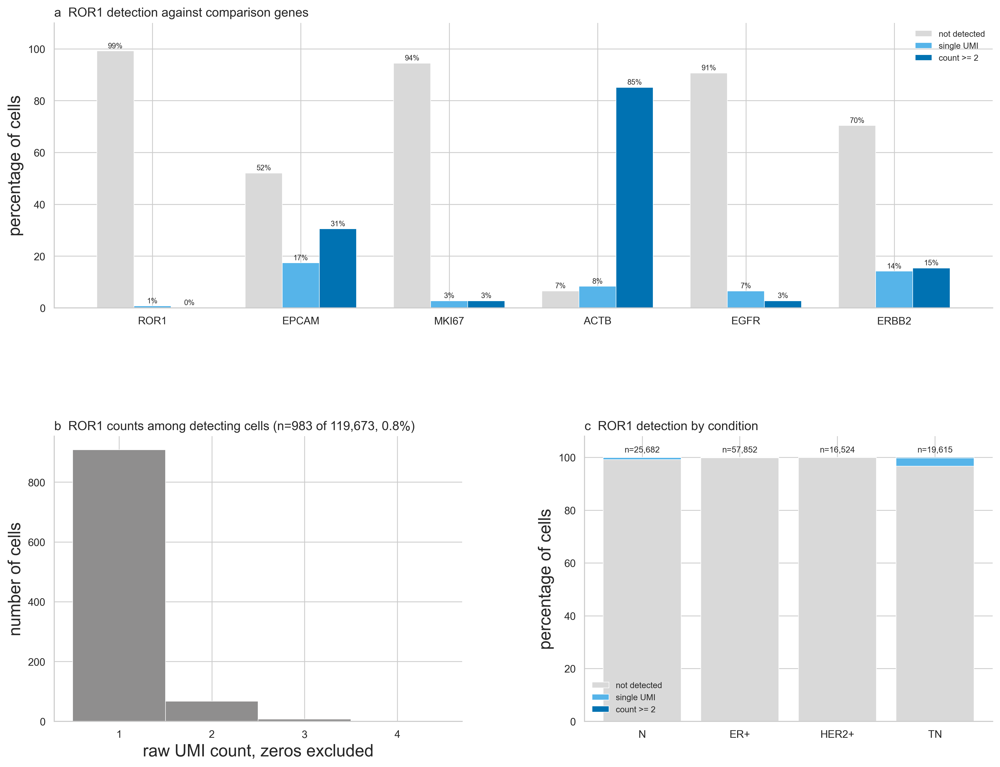

In [36]:
detection_palette = {
    "not detected": "#D9D9D9",
    "single UMI": "#56B4E9",
    "count >= 2": "#0072B2",
}

fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(
    2, 2,
    figure=fig,
    hspace=0.45,
    wspace=0.30,
)

# a: detection classes per gene
ax = fig.add_subplot(gs[0, :])

genes = list(comparison_genes)
x = np.arange(len(genes))
width = 0.25

for offset, column, label in [
    (-width, "pct_zero", "not detected"),
    (0.0, "pct_count1", "single UMI"),
    (width, "pct_count2plus", "count >= 2"),
]:
    bars = ax.bar(
        x + offset,
        detection_stats.loc[genes, column],
        width,
        label=label,
        color=detection_palette[label],
        edgecolor="white",
        linewidth=0.5,
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{bar.get_height():.0f}%",
            ha="center",
            va="bottom",
            fontsize=7,
        )

ax.set_xticks(x)
ax.set_xticklabels(genes, fontsize=10)
ax.set_ylabel("percentage of cells")
ax.set_ylim(0, 110)
ax.set_title(
    "a  ROR1 detection against comparison genes",
    fontsize=12,
    loc="left",
)
ax.legend(fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)


# b: ROR1 counts among detecting cells
ax = fig.add_subplot(gs[1, 0])

nonzero = ror1[ror1 > 0]
max_count = int(ror1.max())

ax.hist(
    nonzero,
    bins=np.arange(0.5, max_count + 1.5),
    color="#8F8E8E",
    edgecolor="white",
    linewidth=0.5,
)

ax.set_xlabel("raw UMI count, zeros excluded")
ax.set_ylabel("number of cells")
ax.set_xticks(range(1, max_count + 1))
ax.set_title(
    f"b  ROR1 counts among detecting cells "
    f"(n={len(nonzero):,} of {len(ror1):,}, "
    f"{100 * len(nonzero) / len(ror1):.1f}%)",
    fontsize=12,
    loc="left",
)
ax.spines[["top", "right"]].set_visible(False)


# c: detection classes per condition
ax = fig.add_subplot(gs[1, 1])

condition_values = epi.obs["condition"].astype(str).to_numpy()

zero_pct = []
one_pct = []
two_pct = []

for condition in conditions:
    values = ror1[condition_values == condition]

    zero_pct.append(100 * (values == 0).mean())
    one_pct.append(100 * (values == 1).mean())
    two_pct.append(100 * (values >= 2).mean())

x = np.arange(len(conditions))

ax.bar(
    x,
    zero_pct,
    label="not detected",
    color=detection_palette["not detected"],
    edgecolor="white",
    linewidth=0.5,
)

ax.bar(
    x,
    one_pct,
    bottom=zero_pct,
    label="single UMI",
    color=detection_palette["single UMI"],
    edgecolor="white",
    linewidth=0.5,
)

ax.bar(
    x,
    two_pct,
    bottom=np.add(zero_pct, one_pct),
    label="count >= 2",
    color=detection_palette["count >= 2"],
    edgecolor="white",
    linewidth=0.5,
)

for i, condition in enumerate(conditions):
    n_cells = int((condition_values == condition).sum())
    ax.text(
        i,
        102,
        f"n={n_cells:,}",
        ha="center",
        fontsize=8,
    )

ax.set_xticks(x)
ax.set_xticklabels(conditions)
ax.set_ylabel("percentage of cells")
ax.set_ylim(0, 108)
ax.set_title(
    "c  ROR1 detection by condition",
    fontsize=12,
    loc="left",
)
ax.legend(fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig(
    fig_dir / "ror1_dropout.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## ALRA imputation



Run per sample on the log-normalised expression of the integration gene set,
with the reconstruction rank chosen automatically by choose_k, the
singular-value search capped at 100 dimensions. ALRA output is used for visualisation only; every
threshold in this notebook is applied to raw counts.

In [37]:
# the deviance-ranked set plus the targets. This does not depend on whether the protected genes were added to the scVI feature set in 003a, so ALRA and the integration are selected independently.
alra_genes = epi.var_names[epi.var["highly_variable_deviance"]].tolist()
alra_genes = list(dict.fromkeys(alra_genes + target_genes))

In [38]:
for gene in target_genes:
    assert gene in alra_genes, gene

In [39]:
len(alra_genes)

4003

In [40]:
ro.r('''
    suppressPackageStartupMessages({
        library(ALRA)
        library(rsvd)
    })

    options(mem.maxVSize = Inf)
    set.seed(0)
''')

In [41]:
gene_position = {gene: i for i, gene in enumerate(alra_genes)}

In [42]:
alra_values = {
    gene: np.full(epi.n_obs, np.nan, dtype=np.float32) for gene in target_genes
}

In [43]:
alra_ranks = []

In [44]:
for sample in epi.obs["sample"].astype(str).unique():

    mask = (epi.obs["sample"].astype(str) == sample).to_numpy()
    n_cells = int(mask.sum())

    if n_cells < 50:
        print(f"skipping {sample}: {n_cells} cells")
        continue

    x_sample = epi[mask, alra_genes].layers["lognorm"]
    x_sample = x_sample.toarray() if sp.issparse(x_sample) else np.asarray(x_sample)
    x_sample = np.ascontiguousarray(x_sample, dtype=np.float32)

    assert np.isfinite(x_sample).all()
    assert x_sample.min() >= 0

    # the rank search is bounded by the matrix, not by a fixed rank
    k_search = int(min(100, min(x_sample.shape) - 1))
    noise_start = int(max(1, k_search - 20))

    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["X_sub"] = x_sample

    ro.globalenv["k_search"] = ro.IntVector([k_search])
    ro.globalenv["noise_start"] = ro.IntVector([noise_start])

    # choose_k reads the rank off the singular-value spacings; if it cannot, the fallback is recorded per sample rather than passing silently
    ro.r('''
        k_choice <- try(
            choose_k(X_sub, K = k_search, noise_start = noise_start),
            silent = TRUE
        )

        if (inherits(k_choice, "try-error")) {
            k_use <- k_search
            k_auto <- FALSE
        } else {
            k_use <- k_choice$k
            k_auto <- TRUE
        }

        result <- alra(X_sub, k = k_use)
        X_imp <- as.matrix(result[[3]])
    ''')

    k_use = int(np.asarray(ro.globalenv["k_use"]).ravel()[0])
    k_auto = bool(np.asarray(ro.globalenv["k_auto"]).ravel()[0])

    x_imputed = np.asarray(ro.globalenv["X_imp"], dtype=np.float32)

    assert x_imputed.shape == x_sample.shape

    for gene in target_genes:
        alra_values[gene][mask] = x_imputed[:, gene_position[gene]]

    alra_ranks.append({
        "sample": sample,
        "n_cells": n_cells,
        "k_search": k_search,
        "alra_k": k_use,
        "rank_chosen_automatically": k_auto,
    })

    print(f"{sample}: {n_cells:,} cells, k = {k_use}"
          f"{'' if k_auto else '  (choose_k failed, fell back to k_search)'}")

    ro.r("rm(X_sub, X_imp, result, k_choice); gc()")

    del x_sample, x_imputed
    gc.collect()

Read matrix with 3156 cells and 4003 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 69 columns
0.04% of the values became negative in the scaling process and were set to zero
The matrix went from 28.26% nonzero to 54.86% nonzero
GSM4909253_N-PM0092-Total: 3,156 cells, k = 43
Read matrix with 3831 cells and 4003 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 69 columns
0.06% of the values became negative in the scaling process and were set to zero
The matrix went from 31.06% nonzero to 61.90% nonzero
GSM4909254_N-PM0019-Total: 3,831 cells, k = 41
Read matrix with 2221 cells and 4003 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 71 columns
0.32% of the values became negative in the scaling process and were set to zero
The matrix went from 33.78% nonzero to 60.54% nonzero
GSM4909257_N-PM0095-Total: 2,221 cells,

In [45]:
for gene in target_genes:
    epi.obs[f"{gene}_alra"] = alra_values[gene]

In [46]:
alra_ranks = pd.DataFrame(alra_ranks)

In [47]:
alra_ranks

,sample,n_cells,k_search,alra_k,rank_chosen_automatically
0,GSM4909253_N-PM0092-Total,3156,100,43,True
1,GSM4909254_N-PM0019-Total,3831,100,41,True
2,GSM4909257_N-PM0095-Total,2221,100,34,True
3,GSM4909261_N-PM0230-Total,815,100,22,True
4,GSM4909263_N-MH0064-Total,715,100,18,True
5,GSM4909265_N-PM0233-Total,2048,100,39,True
6,GSM4909266_N-MH0169-Total,724,100,24,True
7,GSM4909268_N-MH0023-Total,4071,100,38,True
8,GSM4909270_N-PM0342-Total,4361,100,39,True
9,GSM4909272_N-MH0021-Total,1232,100,15,True


In [48]:
n_fallback = int((~alra_ranks["rank_chosen_automatically"]).sum())

In [49]:
if n_fallback:
    print(f"\\n{n_fallback} sample(s) fell back to k_search")

In [50]:
alra_ranks.to_csv(df_dir / "alra_rank_per_sample.csv", index=False)

In [51]:
epi.uns["alra"] = {
    "purpose": "visualisation and dropout reconstruction only",
    "input_layer": "lognorm",
    "run_per_sample": True,
    "rank_selection": "ALRA choose_k on the singular-value spacings",
    "k_search_cap": 100,
    "noise_gap": 20,
    "n_features": int(len(alra_genes)),
    "feature_set": "deviance-ranked genes plus target genes",
    "target_genes": target_genes,
    "n_samples_fallback": n_fallback,
}

In [52]:
# imputation must not have touched the raw counts
after = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}

In [53]:
assert after == baseline_positive, (baseline_positive, after)

In [54]:
rows = []

In [55]:
for gene in target_genes:

    raw = raw_counts(epi, gene)
    imputed = epi.obs[f"{gene}_alra"].to_numpy()

    rows.append({
        "gene": gene,
        "raw_detected_pct": 100 * (raw > 0).mean(),
        "alra_nonzero_pct": 100 * (imputed > 0).mean(),
        "median_alra_where_raw_zero": np.nanmedian(imputed[raw == 0]),
        "median_alra_where_raw_positive": np.nanmedian(imputed[raw > 0]),
    })

In [56]:
alra_summary = pd.DataFrame(rows)

In [57]:
alra_summary.round(3)

,gene,raw_detected_pct,alra_nonzero_pct,median_alra_where_raw_zero,median_alra_where_raw_positive
0,ROR1,0.821,6.249,0.000,0.625
1,ROR2,2.191,18.159,0.000,0.867
2,EGFR,9.345,27.792,0.000,0.933
3,ERBB2,29.586,76.005,0.698,1.585
4,EPCAM,47.944,87.615,1.029,1.661


In [58]:
alra_summary.to_csv(df_dir / "alra_target_gene_summary.csv", index=False)

In [59]:
# what value ALRA assigns to a cell at each observed raw count
frames = []

In [60]:
for gene in target_genes:

    raw = raw_counts(epi, gene)

    frames.append(pd.DataFrame({
        "gene": gene,
        "raw_umi": np.where(raw >= 3, "3+", raw.astype(int).astype(str)),
        "alra": epi.obs[f"{gene}_alra"].to_numpy(),
    }))

In [61]:
alra_long = pd.concat(frames, ignore_index=True)

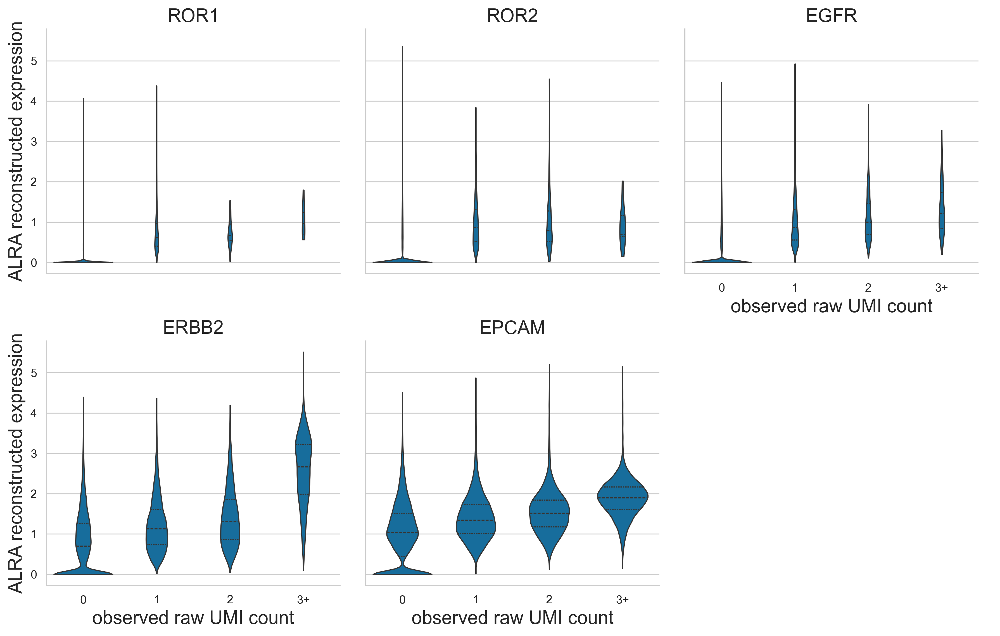

In [62]:
g = sns.catplot(
    data=alra_long,
    x="raw_umi",
    y="alra",
    col="gene",
    col_wrap=3,
    order=["0", "1", "2", "3+"],
    kind="violin",
    cut=0,
    inner="quartile",
    height=4,
    aspect=1,
)

g.set_axis_labels("observed raw UMI count", "ALRA reconstructed expression")
g.set_titles("{col_name}")

plt.savefig(fig_dir / "alra_reconstruction_by_raw_count.png", dpi=300, bbox_inches="tight")
plt.show()

In [63]:
# shared condition colours, also used by the Figure 2b,c panels below
condition_palette_supp = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}

In [64]:
# Supplementary Figure 2e,f -- ROR1 after imputation, by condition. The raw panels (c,d) are in the dropout figure above; these are the imputed counterparts, on the same conditions and the same stacking.
ror1_alra = epi.obs["ROR1_alra"].to_numpy()

In [65]:
condition_values = epi.obs["condition"].astype(str).to_numpy()

In [66]:
alra_bins = [(0.1, 1.0, "> 0.1 - 1"), (1.0, 2.0, "> 1 - 2"),
             (2.0, 3.0, "> 2 - 3"), (3.0, np.inf, "> 3")]

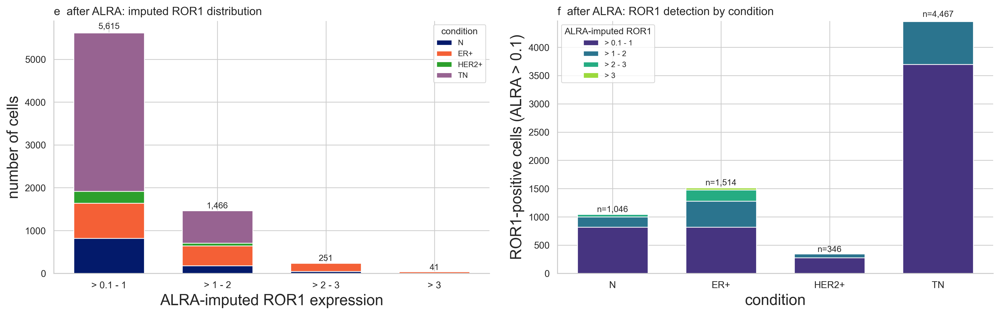

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# e: how many cells fall in each imputed-expression bin, stacked by condition
ax = axes[0]
x = np.arange(len(alra_bins))
bottom = np.zeros(len(alra_bins))

for condition in conditions:
    values = np.array([
        int(((ror1_alra > lo) & (ror1_alra <= hi) & (condition_values == condition)).sum())
        for lo, hi, _ in alra_bins
    ])
    ax.bar(x, values, bottom=bottom, label=condition,
           color=condition_palette_supp[condition], width=0.65)
    bottom += values

for xi, total in enumerate(bottom):
    if total > 0:
        ax.text(xi, total * 1.01, f"{int(total):,}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([label for _, _, label in alra_bins])
ax.set_xlabel("ALRA-imputed ROR1 expression")
ax.set_ylabel("number of cells")
ax.set_title("e  after ALRA: imputed ROR1 distribution", fontsize=12, loc="left")
ax.legend(title="condition", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

# f: ROR1-positive cells per condition, stacked by imputed-expression bin
ax = axes[1]
x = np.arange(len(conditions))
bottom = np.zeros(len(conditions))
shades = plt.cm.viridis(np.linspace(0.15, 0.85, len(alra_bins)))

for (lo, hi, label), colour in zip(alra_bins, shades):
    values = np.array([
        int(((ror1_alra > lo) & (ror1_alra <= hi) & (condition_values == c)).sum())
        for c in conditions
    ])
    ax.bar(x, values, bottom=bottom, label=label, color=colour, width=0.65)
    bottom += values

for xi, total in enumerate(bottom):
    ax.text(xi, total * 1.01, f"n={int(total):,}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(conditions)
ax.set_xlabel("condition")
ax.set_ylabel("ROR1-positive cells (ALRA > 0.1)")
ax.set_title("f  after ALRA: ROR1 detection by condition", fontsize=12, loc="left")
ax.legend(title="ALRA-imputed ROR1", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(fig_dir / "ror1_alra_by_condition.png", dpi=300, bbox_inches="tight")
plt.show()

In [68]:
# the same counts as a table, since these are quoted in the supplement
alra_detection = pd.DataFrame([
    {"condition": c,
     **{label: int(((ror1_alra > lo) & (ror1_alra <= hi) & (condition_values == c)).sum())
        for lo, hi, label in alra_bins},
     "total_alra_positive": int(((ror1_alra > 0.1) & (condition_values == c)).sum()),
     "raw_positive": int((raw_counts(epi, "ROR1")[condition_values == c] > 0).sum())}
    for c in conditions
])

In [69]:
alra_detection

,condition,> 0.1 - 1,> 1 - 2,> 2 - 3,> 3,total_alra_positive,raw_positive
0,N,819,180,44,3,1046,213
1,ER+,819,462,195,38,1514,91
2,HER2+,279,67,0,0,346,17
3,TN,3698,757,12,0,4467,662


In [70]:
alra_detection.to_csv(df_dir / "ror1_alra_detection_by_condition.csv", index=False)

## Antigen expression on the epithelial UMAP


In [71]:

#EPCAM, ERBB2 and EGFR are shown as log-normalised expression. ROR1 is shown as ALRA-imputed expression because of its dropout, and the two scales are labelled separately rather than shared.

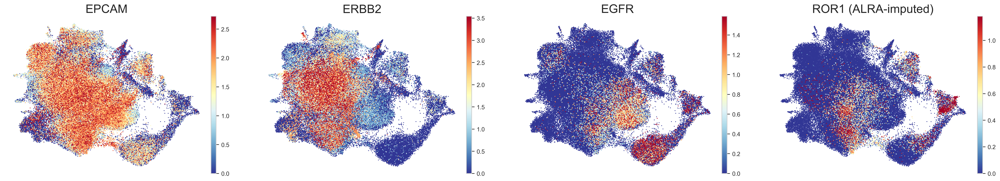

In [225]:
sc.pl.umap(
    epi,
    color=["EPCAM", "ERBB2", "EGFR", "ROR1_alra"],
    title=["EPCAM", "ERBB2", "EGFR", "ROR1 (ALRA-imputed)"],
    ncols=4,
    cmap="RdYlBu_r",
    vmax="p99",
    size=8,
    frameon=False,
    show=False,
)

plt.savefig(fig_dir / "antigen_expression_umap.svg", dpi=300, bbox_inches="tight")
plt.show()

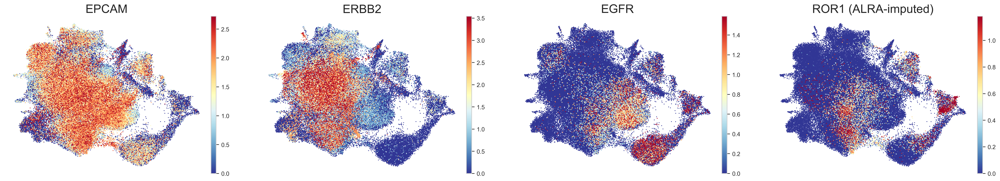

In [72]:
sc.pl.umap(
    epi,
    color=["EPCAM", "ERBB2", "EGFR", "ROR1_alra"],
    title=["EPCAM", "ERBB2", "EGFR", "ROR1 (ALRA-imputed)"],
    ncols=4,
    cmap="RdYlBu_r",
    vmax="p99",
    size=8,
    frameon=False,
    show=False,
)

plt.savefig(fig_dir / "antigen_expression_umap.svg", dpi=300, bbox_inches="tight")
plt.show()

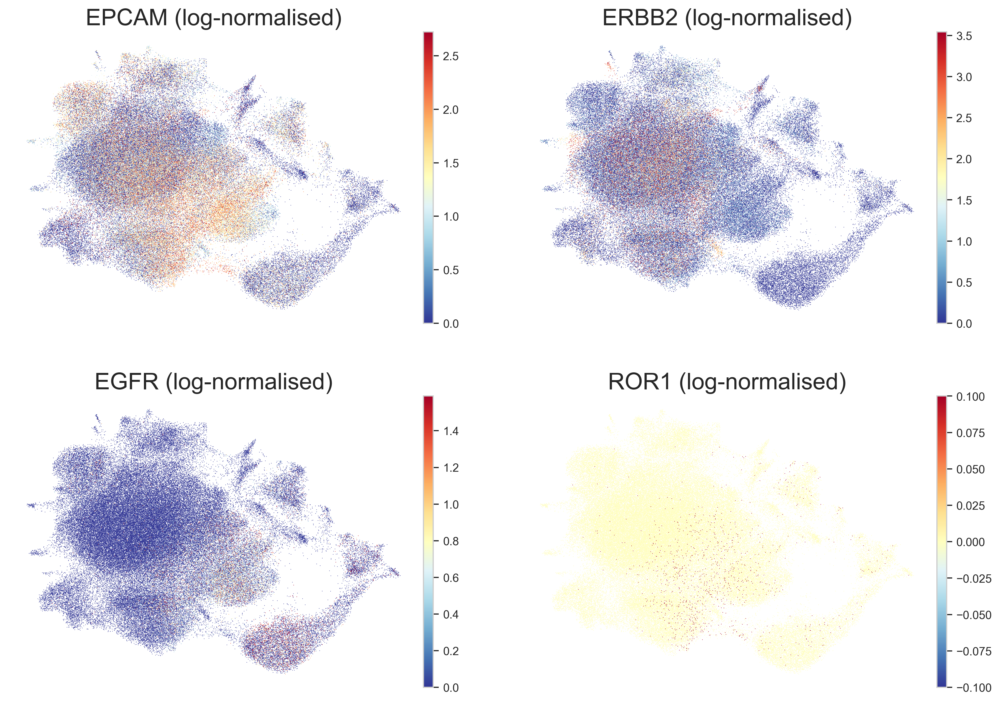

In [73]:
# the same four genes without imputation, for direct comparison
sc.pl.umap(
    epi,
    color=["EPCAM", "ERBB2", "EGFR", "ROR1"],
    title=[f"{g} (log-normalised)" for g in ["EPCAM", "ERBB2", "EGFR", "ROR1"]],
    ncols=2,
    cmap="RdYlBu_r",
    vmax="p99",
    frameon=False,
    show=False,
)

plt.savefig(fig_dir / "antigen_expression_umap_raw.png", dpi=300, bbox_inches="tight")
plt.show()

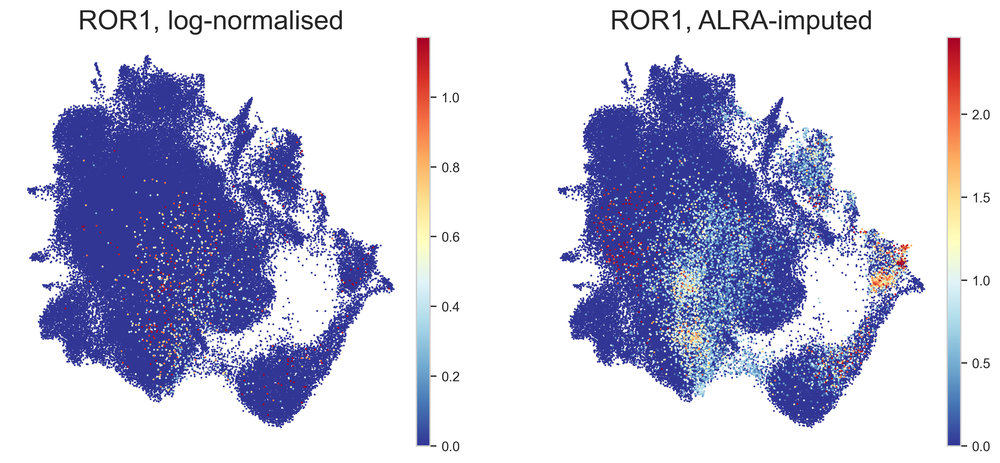

In [74]:
# ROR1 before and after imputation, on the same embedding. The two panels keep separate colour bars: log-normalised counts and ALRA output are different quantities and a shared scale would misrepresent both.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sc.pl.umap(epi, color="ROR1", layer="lognorm", cmap="RdYlBu_r", vmax="p99.9",
           size=8, frameon=False, title="ROR1, log-normalised", ax=axes[0], show=False)

sc.pl.umap(epi, color="ROR1_alra", cmap="RdYlBu_r", vmax="p99.9",
           size=8, frameon=False, title="ROR1, ALRA-imputed", ax=axes[1], show=False)

plt.savefig(fig_dir / "ror1_before_after_alra_umap.png", dpi=300, bbox_inches="tight")
plt.show()

In [75]:
ror1_raw_lognorm = np.asarray(epi[:, "ROR1"].layers["lognorm"].todense()).ravel()

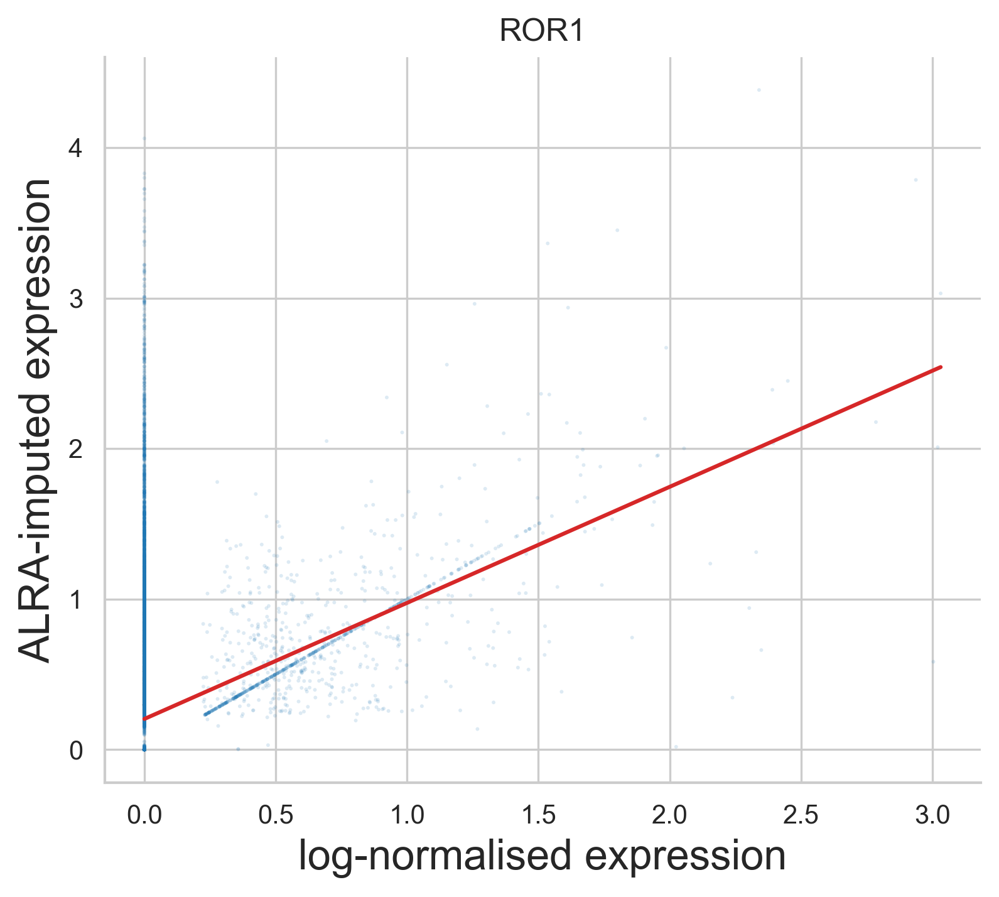

In [76]:
# Supplementary Figure 2b - what ALRA assigns against what was observed
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(ror1_raw_lognorm, epi.obs["ROR1_alra"], s=2, alpha=0.15,
           color="#1f77b4", edgecolors="none")

detected = ror1_raw_lognorm > 0

fit = np.polyfit(ror1_raw_lognorm[detected], epi.obs["ROR1_alra"].to_numpy()[detected], 1)
xs = np.linspace(0, ror1_raw_lognorm.max(), 100)
ax.plot(xs, np.polyval(fit, xs), color="#d62728", linewidth=1.5)

ax.set_xlabel("log-normalised expression")
ax.set_ylabel("ALRA-imputed expression")
ax.set_title("ROR1", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig(fig_dir / "ror1_alra_vs_observed.png", dpi=300, bbox_inches="tight")
plt.show()

In [77]:
# how much of the zero class ALRA fills, per target
recovery = pd.DataFrame([
    {"gene": g,
     "raw_zero_%": round(100 * (raw_counts(epi, g) == 0).mean(), 1),
     "alra_positive_among_raw_zero_%": round(
         100 * (epi.obs[f"{g}_alra"].to_numpy()[raw_counts(epi, g) == 0] > 0).mean(), 1),
     "alra_positive_%": round(100 * (epi.obs[f"{g}_alra"] > 0).mean(), 1)}
    for g in target_genes
])

recovery.to_csv(df_dir / "alra_zero_recovery.csv", index=False)
recovery

,gene,raw_zero_%,alra_positive_among_raw_zero_%,alra_positive_%
0,ROR1,99.2,5.5,6.2
1,ROR2,97.8,16.3,18.2
2,EGFR,90.7,20.3,27.8
3,ERBB2,70.4,65.9,76.0
4,EPCAM,52.1,76.2,87.6


## Antigen-pair co-expression

Positivity is called on raw counts, at one threshold shared by both pairs, so
that their prevalences are directly comparable.

In [78]:
def gene_positive(adata, gene, min_umi):
    # ROR1 is thresholded on ALRA-imputed expression because of its dropout; every other gene keeps raw-UMI thresholding
    if gene == "ROR1":
        return adata.obs["ROR1_alra"].to_numpy() > ror1_alra_positive_threshold
    return raw_counts(adata, gene) >= min_umi

def coexpression_group(adata, gene_a, gene_b, min_umi):
    a = gene_positive(adata, gene_a, min_umi)
    b = gene_positive(adata, gene_b, min_umi)

    labels = np.full(adata.n_obs, "Double negative", dtype=object)
    labels[a & ~b] = f"{gene_a} only"
    labels[~a & b] = f"{gene_b} only"
    labels[a & b] = "Double positive"

    return pd.Categorical(
        labels,
        categories=["Double negative", f"{gene_a} only", f"{gene_b} only", "Double positive"],
        ordered=True,
    )

In [79]:
for gene_a, gene_b in antigen_pairs:

    column = f"{gene_a}_{gene_b}_group"
    epi.obs[column] = coexpression_group(epi, gene_a, gene_b, primary_min_umi)

    n = int((epi.obs[column] == "Double positive").sum())
    print(f"{column}: {n:,} double positive ({100 * n / epi.n_obs:.3f}%)")

ROR1_EGFR_group: 1,599 double positive (1.336%)
EPCAM_ERBB2_group: 23,782 double positive (19.872%)


In [80]:
epi.uns["coexpression"] = {
    "expression": "raw UMI counts",
    "min_umi": primary_min_umi,
    "pairs": ["-".join(pair) for pair in antigen_pairs],
    "note": "ALRA values are not used for thresholding",
}

In [81]:
# both pairs at every threshold, whole epithelial compartment and per condition
rows = []

In [82]:
# the loop variable is deliberately not called min_umi: rebinding the primary threshold here would silently change every analysis below
for threshold_umi in min_umi_sweep:
    for gene_a, gene_b in antigen_pairs:

        groups = coexpression_group(epi, gene_a, gene_b, threshold_umi)
        double_positive = np.asarray(groups == "Double positive")

        rows.append({
            "pair": f"{gene_a}-{gene_b}",
            "min_umi": threshold_umi,
            "condition": "all",
            "n_cells": epi.n_obs,
            "n_double_positive": int(double_positive.sum()),
            "pct_double_positive": 100 * double_positive.mean(),
        })

        for condition in conditions:

            mask = (epi.obs["condition"].astype(str) == condition).to_numpy()

            rows.append({
                "pair": f"{gene_a}-{gene_b}",
                "min_umi": threshold_umi,
                "condition": condition,
                "n_cells": int(mask.sum()),
                "n_double_positive": int(double_positive[mask].sum()),
                "pct_double_positive": 100 * double_positive[mask].mean(),
            })

In [83]:
threshold_sweep = pd.DataFrame(rows)

In [84]:
threshold_sweep .pivot_table(index=["pair", "condition"], columns="min_umi", values="pct_double_positive") .round(3) 

min_umi                     1       2       3
pair        condition                        
EPCAM-ERBB2 ER+        12.127   3.611   1.352
            HER2+      59.235  42.163  31.929
            N          14.185   3.734   1.075
            TN         17.002   3.406   0.775
            all        19.872   8.927   5.420
ROR1-EGFR   ER+         0.315   0.052   0.016
            HER2+       0.309   0.073   0.030
            N           1.445   0.650   0.339
            TN          5.073   0.902   0.224
            all         1.336   0.323   0.121

In [85]:
threshold_sweep.to_csv(df_dir / "coexpression_threshold_sweep.csv", index=False)

In [86]:
# the descriptive figures use all epithelial cells, because the normal compartment is the comparator; tumour-biology statements are restricted to the CNV-defined malignant cells
malignant_only = epi.obs["malignant"].to_numpy()

In [87]:
rows = []

In [88]:
for gene_a, gene_b in antigen_pairs:

    double_positive = np.asarray(
        coexpression_group(epi, gene_a, gene_b, primary_min_umi) == "Double positive"
    )

    for scope, scope_mask in [("all_epithelial", np.ones(epi.n_obs, bool)),
                              ("malignant_only", malignant_only)]:

        for condition in conditions:

            mask = scope_mask & (epi.obs["condition"].astype(str) == condition).to_numpy()

            if mask.sum() == 0:
                continue

            rows.append({
                "pair": f"{gene_a}-{gene_b}",
                "scope": scope,
                "condition": condition,
                "n_cells": int(mask.sum()),
                "n_double_positive": int(double_positive[mask].sum()),
                "pct_double_positive": 100 * double_positive[mask].mean(),
            })

In [89]:
coexpression_by_scope = pd.DataFrame(rows)

In [90]:
coexpression_by_scope .pivot_table(index=["pair", "condition"], columns="scope", values="pct_double_positive") .round(3) 

scope                  all_epithelial  malignant_only
pair        condition                                
EPCAM-ERBB2 ER+                12.127          10.862
            HER2+              59.235          60.656
            N                  14.185             NaN
            TN                 17.002          16.188
ROR1-EGFR   ER+                 0.315           0.259
            HER2+               0.309           0.144
            N                   1.445             NaN
            TN                  5.073           5.157

In [91]:
coexpression_by_scope.to_csv(df_dir / "coexpression_all_vs_malignant.csv", index=False)

In [92]:
# co-detection against the rate expected if the two transcripts were independent
rows = []

In [93]:
for gene_a, gene_b in antigen_pairs:

    a = raw_counts(epi, gene_a) >= primary_min_umi
    b = raw_counts(epi, gene_b) >= primary_min_umi

    for condition in conditions:

        mask = (epi.obs["condition"].astype(str) == condition).to_numpy()

        p_a = a[mask].mean()
        p_b = b[mask].mean()
        observed = (a & b)[mask].mean()
        expected = p_a * p_b

        rows.append({
            "pair": f"{gene_a}-{gene_b}",
            "condition": condition,
            "pct_a": 100 * p_a,
            "pct_b": 100 * p_b,
            "pct_observed": 100 * observed,
            "pct_expected": 100 * expected,
            "observed_over_expected": observed / expected if expected > 0 else np.nan,
        })

In [94]:
independence = pd.DataFrame(rows)

In [95]:
independence.round(3)

,pair,condition,pct_a,pct_b,pct_observed,pct_expected,observed_over_expected
0,ROR1-EGFR,N,0.829,25.617,0.440,0.212,2.071
1,ROR1-EGFR,ER+,0.157,2.354,0.029,0.004,7.935
2,ROR1-EGFR,HER2+,0.103,3.038,0.012,0.003,3.873
3,ROR1-EGFR,TN,3.375,13.969,0.872,0.471,1.849
4,EPCAM-ERBB2,N,59.073,16.175,14.185,9.555,1.485
5,EPCAM-ERBB2,ER+,32.977,22.960,12.127,7.572,1.602
6,EPCAM-ERBB2,HER2+,63.362,82.710,59.235,52.407,1.130
7,EPCAM-ERBB2,TN,64.527,21.932,17.002,14.152,1.201


In [96]:
independence.to_csv(df_dir / "coexpression_observed_over_expected.csv", index=False)

## Tumour versus normal therapeutic window



Everything below uses raw UMI counts. ALRA is used for visualisation only.

The unit of replication is the donor, not the cell. Pooled prevalence and donor-level
prevalence are reported separately because they answer different questions and can
disagree when donors differ greatly in size.

In [97]:
# primary donor eligibility threshold for a stable prevalence estimate. Not preregistered: 0, 50 and 100 were all examined and 100 chosen for the primary table because the pooled ratio is stable across them. Robustness shown below.
min_donor_cells = 100

In [98]:
window_group = np.where(
    epi.obs["condition"].astype(str) == "N",
    "Normal epithelium",
    np.where(malignant_only, epi.obs["condition"].astype(str) + " malignant", "excluded"),
)

In [99]:
ror1_positive = raw_counts(epi, "ROR1") >= primary_min_umi
egfr_positive = raw_counts(epi, "EGFR") >= primary_min_umi

In [100]:
assert "patient" in epi.obs.columns, "patient metadata is required for donor-level inference"
assert epi.obs["patient"].notna().all(), "patient metadata contains missing values"

window = pd.DataFrame({
    "group": window_group,
    "patient": epi.obs["patient"].astype(str).to_numpy(),
    "sample": epi.obs["sample"].astype(str).to_numpy(),
    "ror1": ror1_positive,
    "egfr": egfr_positive,
    "double_positive": ror1_positive & egfr_positive,
})

window = window[window["group"] != "excluded"]

In [101]:
by_donor = (
    window.groupby(["group", "patient"], observed=True)
    .agg(n_cells=("double_positive", "size"),
         n_ror1=("ror1", "sum"),
         n_egfr=("egfr", "sum"),
         n_double_positive=("double_positive", "sum"))
    .reset_index()
)

by_donor["prevalence"] = by_donor["n_double_positive"] / by_donor["n_cells"] * 100

In [102]:
def summarise_window(frame):
    """pooled and donor-level statistics side by side, never merged into one column"""
    rows = []

    for group, g in frame.groupby("group", observed=True):

        rows.append({
            "group": group,
            "donors": len(g),
            "total_cells": int(g["n_cells"].sum()),
            "total_double_positive": int(g["n_double_positive"].sum()),
            "pooled_pct": g["n_double_positive"].sum() / g["n_cells"].sum() * 100,
            "donor_mean_pct": g["prevalence"].mean(),
            "donor_median_pct": g["prevalence"].median(),
            "donor_q1_pct": g["prevalence"].quantile(0.25),
            "donor_q3_pct": g["prevalence"].quantile(0.75),
            "donors_with_signal": int((g["n_double_positive"] > 0).sum()),
        })

    return pd.DataFrame(rows)

In [103]:
eligible_donors = by_donor[by_donor["n_cells"] >= min_donor_cells]

therapeutic_window = summarise_window(eligible_donors)
therapeutic_window.to_csv(df_dir / "coexpression_therapeutic_window.csv", index=False)

In [104]:
therapeutic_window.round(4)

,group,donors,total_cells,total_double_positive,pooled_pct,donor_mean_pct,donor_median_pct,donor_q1_pct,donor_q3_pct,donors_with_signal
0,ER+ malignant,8,50158,9,0.0179,0.0241,0.0000,0.0000,0.0240,3
1,HER2+ malignant,1,15263,0,0.0000,0.0000,0.0000,0.0000,0.0000,0
2,Normal epithelium,12,25682,113,0.4400,0.4251,0.3411,0.1781,0.5043,10
3,TN malignant,3,17606,145,0.8236,0.5094,0.5797,0.2898,0.7641,2


In [105]:
# the eligibility rule should not decide the answer
rows = []

for rule in [0, 50, 100]:

    summary = summarise_window(by_donor[by_donor["n_cells"] >= rule]).set_index("group")

    tn = summary.loc["TN malignant"]
    normal = summary.loc["Normal epithelium"]

    rows.append({
        "min_donor_cells": rule,
        "tn_donors": int(tn["donors"]),
        "tn_pooled_pct": tn["pooled_pct"],
        "tn_donor_mean_pct": tn["donor_mean_pct"],
        "normal_pooled_pct": normal["pooled_pct"],
        "pooled_ratio": tn["pooled_pct"] / normal["pooled_pct"],
    })

eligibility_sensitivity = pd.DataFrame(rows)
eligibility_sensitivity.to_csv(df_dir / "coexpression_eligibility_sensitivity.csv", index=False)

In [106]:
eligibility_sensitivity.round(4)

,min_donor_cells,tn_donors,tn_pooled_pct,tn_donor_mean_pct,normal_pooled_pct,pooled_ratio
0,0,3,0.8236,0.5094,0.44,1.8718
1,50,3,0.8236,0.5094,0.44,1.8718
2,100,3,0.8236,0.5094,0.44,1.8718


In [107]:
# ROR1 and EGFR are both lowly detected, so co-detection is sensitive to library size. Thin every cell to a common depth and see whether the contrast survives.
rarefaction_depths = [1000, 2000, 3000]
n_rarefactions = 100
rarefaction_seed = 0

In [108]:
# hypergeometric sampling needs integer counts, and the sparse row sums come back as float
library_size = np.asarray(epi.layers["counts"].sum(axis=1)).ravel().astype(np.int64)

ror1_counts = raw_counts(epi, "ROR1").astype(np.int64)
egfr_counts = raw_counts(epi, "EGFR").astype(np.int64)

In [109]:
# eligibility and the cell set are both fixed at the deepest thinning, so that a depth effect cannot be confounded with a change in which cells contribute
deepest = max(rarefaction_depths)

sample_values = epi.obs["sample"].astype(str).to_numpy()
patient_values = epi.obs["patient"].astype(str).to_numpy()

deep_mask = (library_size >= deepest) & (window_group != "excluded")

retained = pd.DataFrame({"patient": patient_values[deep_mask], "group": window_group[deep_mask]})
retained_per_donor = retained.groupby(["group", "patient"], observed=True).size()

fixed_donor_groups = set(
    retained_per_donor[retained_per_donor >= min_donor_cells].index.to_list()
)

# exactly these cells are used at 1,000, 2,000 and 3,000 UMI
cell_donor_groups = pd.MultiIndex.from_arrays([window_group, patient_values])
fixed_cell_mask = deep_mask & cell_donor_groups.isin(fixed_donor_groups)

In [110]:
def rarefied_prevalence(depth, seed):
    """Exact rarefaction on a fixed cell set. ROR1 is drawn hypergeometrically from
    the cell's whole transcriptome; EGFR is then drawn from what is left, so the two
    antigens are sampled jointly rather than thinned independently."""
    rng = np.random.default_rng(seed)

    ror1_drawn = rng.hypergeometric(
        ror1_counts[fixed_cell_mask],
        library_size[fixed_cell_mask] - ror1_counts[fixed_cell_mask],
        depth,
    )

    remaining = depth - ror1_drawn

    egfr_drawn = rng.hypergeometric(
        egfr_counts[fixed_cell_mask],
        library_size[fixed_cell_mask] - ror1_counts[fixed_cell_mask] - egfr_counts[fixed_cell_mask],
        remaining,
    )

    frame = pd.DataFrame({
        "group": window_group[fixed_cell_mask],
        "patient": patient_values[fixed_cell_mask],
        "hit": (ror1_drawn > 0) & (egfr_drawn > 0),
    })

    return frame.groupby(["group", "patient"], observed=True).agg(
        n_cells=("hit", "size"), n_hit=("hit", "sum")
    )

In [111]:
retained_per_donor.rename("cells_at_deepest_rarefaction").to_frame().assign(
    eligible=lambda d: d.index.isin(fixed_donor_groups)
)

cells_at_deepest_rarefaction  eligible
group             patient                                          
ER+ malignant     ER                                13330      True
                  ER-MH0029                          4894      True
                  ER-MH0043                          1402      True
                  ER-MH0056                            32     False
                  ER-MH0064                            46     False
                  ER-MH0114                          1016      True
                  ER-MH0167                          3260      True
                  ER-MH0173                          1993      True
HER2+ malignant   HER2                              11473      True
Normal epithelium N-MH0021                            145      True
                  N-MH0023                           2803      True
                  N-MH0064                            410      True
                  N-MH0169                            524      True
                  N-MH275                             670      True
                  N-PM0019                           3105      True
                  N-PM0092                           2201      True
                  N-PM0095                           1743      True
                  N-PM0230                            725      True
                  N-PM0233                           1664      True
                  N-PM0342                           2367      True
                  N-PM0372                           1498      True
TN malignant      TN                                 4517      True
                  TN-B1                              9461      True
                  TN-MH0114                            59     False

In [112]:
rows = []

for depth in rarefaction_depths:
    for replicate in range(n_rarefactions):

        donor = rarefied_prevalence(depth, rarefaction_seed + replicate)
        prevalence = (donor["n_hit"] / donor["n_cells"] * 100).groupby("group").mean()

        rows.append({
            "depth": depth,
            "replicate": replicate,
            "tn": prevalence.get("TN malignant", np.nan),
            "normal": prevalence.get("Normal epithelium", np.nan),
        })

rarefaction = pd.DataFrame(rows)
rarefaction["ratio"] = rarefaction["tn"] / rarefaction["normal"]

In [113]:
# at shallow depths a replicate can yield zero normal double positives, making the ratio undefined. Quantiles are taken over the finite ratios and the number of undefined replicates is reported rather than silently dropped.
finite_ratio = np.isfinite(rarefaction["ratio"])

depth_sensitivity = rarefaction.groupby("depth").apply(
    lambda g: pd.Series({
        "tn_median": g["tn"].median(),
        "normal_median": g["normal"].median(),
        "ratio_median": g.loc[np.isfinite(g["ratio"]), "ratio"].median(),
        "ratio_p2_5": g.loc[np.isfinite(g["ratio"]), "ratio"].quantile(0.025),
        "ratio_p97_5": g.loc[np.isfinite(g["ratio"]), "ratio"].quantile(0.975),
        "iterations_above_one": (g["ratio"] > 1).mean() * 100,
        "undefined_ratio": int((~np.isfinite(g["ratio"])).sum()),
    }),
    include_groups=False,
).reset_index()

depth_sensitivity.to_csv(df_dir / "coexpression_depth_sensitivity.csv", index=False)

In [114]:
depth_sensitivity.round(3)

,depth,tn_median,normal_median,ratio_median,ratio_p2_5,ratio_p97_5,iterations_above_one,undefined_ratio
0,1000,0.011,0.005,1.335,0.000,7.457,69.0,33.0
1,2000,0.054,0.021,2.324,0.626,15.418,92.0,0.0
2,3000,0.115,0.045,2.434,1.302,6.681,99.0,0.0


### Depth-matched donor-level sensitivity


The rarefaction above is a technical check. This is the donor-level version, and it is reported as a sensitivity analysis rather than as confirmatory evidence: the depth and the per-donor cell minimum were not prespecified, and the result depends on both. Detection probability is computed exactly from the multivariate hypergeometric distribution rather than by sampling, so there is no Monte-Carlo noise to confound the comparison.

In [115]:
def probability_both_detected(library, first, second, depth):
    """exact P(at least one of each transcript) when `depth` molecules are drawn
    without replacement from a cell's library"""
    def log_choose(n, k):
        n = np.asarray(n, float)
        out = np.full(n.shape, -np.inf)
        usable = (n >= k) & (n >= 0)
        out[usable] = gammaln(n[usable] + 1) - gammaln(k + 1) - gammaln(n[usable] - k + 1)
        return out

    base = log_choose(library, depth)

    neither_first = np.exp(log_choose(library - first, depth) - base)
    neither_second = np.exp(log_choose(library - second, depth) - base)
    neither = np.exp(log_choose(library - first - second, depth) - base)

    return np.clip(1 - neither_first - neither_second + neither, 0, 1)

In [116]:
# the depth and the per-donor minimum are choices, so both depths are reported
matched_depths = [2000, 3000]
min_cells_per_donor_matched = 30

group_label = np.where(
    epi.obs["condition"].astype(str).to_numpy() == "N",
    "N",
    np.where(malignant_only, epi.obs["condition"].astype(str).to_numpy(), "excluded"),
)

In [117]:
rows = []

for depth in matched_depths:

    eligible = (library_size >= depth) & np.isin(group_label, ["TN", "N"])

    candidate_units = pd.DataFrame({
        "group": group_label[eligible],
        "patient": patient_values[eligible],
    })
    per_donor = candidate_units.groupby(["group", "patient"], observed=True).size()
    eligible_units = set(
        per_donor[per_donor >= min_cells_per_donor_matched].index.to_list()
    )
    all_units = pd.MultiIndex.from_arrays([group_label, patient_values])
    eligible &= all_units.isin(eligible_units)

    probability = probability_both_detected(
        library_size[eligible], ror1_counts[eligible], egfr_counts[eligible], depth
    )

    donor_mean = (
        pd.DataFrame({
            "group": group_label[eligible],
            "patient": patient_values[eligible],
            "probability": probability,
        })
        .groupby(["group", "patient"])["probability"].mean() * 100
    )

    tumour_values = donor_mean.loc["TN"].to_numpy()
    normal_values = donor_mean.loc["N"].to_numpy()

    pooled = np.concatenate([tumour_values, normal_values])
    positions = np.arange(len(pooled))
    difference = tumour_values.mean() - normal_values.mean()

    permuted = np.array([
        pooled[list(assignment)].mean()
        - pooled[np.setdiff1d(positions, assignment, assume_unique=True)].mean()
        for assignment in combinations(positions, len(tumour_values))
    ])

    rows.append({
        "depth": depth,
        "cells": int(eligible.sum()),
        "tn_donors": len(tumour_values),
        "normal_donors": len(normal_values),
        "tn_mean_pct": tumour_values.mean(),
        "normal_mean_pct": normal_values.mean(),
        "difference_pp": difference,
        "exact_permutation_p": float((np.abs(permuted) >= abs(difference)).mean()),
    })

depth_matched_donor = pd.DataFrame(rows)
depth_matched_donor.to_csv(df_dir / "coexpression_depth_matched_donor.csv", index=False)

In [118]:
# the p-value moves with the depth because a seventh TN donor becomes eligible at 2,000 UMI and contributes zero signal. Reported as sensitivity, not as a result.
depth_matched_donor.round(4)

,depth,cells,tn_donors,normal_donors,tn_mean_pct,normal_mean_pct,difference_pp,exact_permutation_p
0,2000,35888,3,12,0.0465,0.0227,0.0239,0.3648
1,3000,31892,3,12,0.0759,0.0452,0.0307,0.4703


In [119]:
# biological inference stays at the donor level
tn_prevalence = eligible_donors.loc[eligible_donors["group"] == "TN malignant", "prevalence"].to_numpy()
normal_prevalence = eligible_donors.loc[eligible_donors["group"] == "Normal epithelium", "prevalence"].to_numpy()

In [120]:
observed_difference = tn_prevalence.mean() - normal_prevalence.mean()

pooled = np.concatenate([tn_prevalence, normal_prevalence])
n_tn = len(tn_prevalence)
all_indices = np.arange(len(pooled))

# few enough donors that the permutation distribution can be enumerated in full, so the p-value carries no Monte-Carlo error
permuted = np.array([
    pooled[list(assignment)].mean()
    - pooled[np.setdiff1d(all_indices, assignment, assume_unique=True)].mean()
    for assignment in combinations(all_indices, n_tn)
])

assert len(permuted) == comb(len(pooled), n_tn)

In [121]:
# the bootstrap carries effect-size uncertainty; the permutation carries the p-value
rng = np.random.default_rng(0)

bootstrapped = np.array([
    rng.choice(tn_prevalence, len(tn_prevalence)).mean()
    - rng.choice(normal_prevalence, len(normal_prevalence)).mean()
    for _ in range(10000)
])

In [122]:
donor_inference = {
    "tn_donor_prevalences": tn_prevalence.tolist(),
    "normal_donor_prevalences": normal_prevalence.tolist(),
    "difference_pp": float(observed_difference),
    "bootstrap_ci_pp": [float(np.percentile(bootstrapped, 2.5)), float(np.percentile(bootstrapped, 97.5))],
    "exact_permutation_p": float((np.abs(permuted) >= abs(observed_difference)).mean()),
    "n_permutations": int(len(permuted)),
    "mann_whitney_p": float(mannwhitneyu(tn_prevalence, normal_prevalence).pvalue),
    "primary_test": "exact permutation on the donor-level difference in mean prevalence; "
                    "Mann-Whitney reported as sensitivity only",
}

epi.uns["coexpression_window"] = donor_inference

In [123]:
donor_inference

{'tn_donor_prevalences': [0.5796592306341121, 0.9485898195985433, 0.0],
 'normal_donor_prevalences': [0.0,
  0.19651191353475803,
  0.0,
  0.5524861878453038,
  0.24242424242424243,
  0.36543983294179067,
  0.3168567807351077,
  1.2606933813597478,
  0.1226993865030675,
  0.48828125,
  0.36688832836505386,
  1.1883541295306002],
 'difference_pp': 0.08436339730757914,
 'bootstrap_ci_pp': [-0.4137745918117982, 0.5518436985515067],
 'exact_permutation_p': 0.789010989010989,
 'n_permutations': 455,
 'mann_whitney_p': 0.7172477187270787,
 'primary_test': 'exact permutation on the donor-level difference in mean prevalence; Mann-Whitney reported as sensitivity only'}

## donor-level co-detection



One point per donor rather than a pooled cell count, so a large tumour cannot dominate the comparison. Tumour groups use CNV-defined malignant cells; the normal group uses all normal epithelial cells, because normal tissue has no malignant compartment. Positivity is raw counts at the primary threshold; the stricter threshold could be a supplementary panel.

In [124]:
def donor_prevalence(gene_a, gene_b, min_umi):
    """one row per donor: eligible cells and the fraction positive for both genes"""
    positive = (raw_counts(epi, gene_a) >= min_umi) & (raw_counts(epi, gene_b) >= min_umi)

    frame = pd.DataFrame({
        "group": window_group,
        "patient": patient_values,
        "double_positive": positive,
    })
    frame = frame[frame["group"] != "excluded"]

    donor = (frame.groupby(["group", "patient"], observed=True)
             .agg(n_cells=("double_positive", "size"),
                  n_double_positive=("double_positive", "sum"))
             .reset_index())

    donor["prevalence"] = donor["n_double_positive"] / donor["n_cells"] * 100
    donor["pair"] = f"{gene_a}+{gene_b}"
    donor["min_umi"] = min_umi

    return donor[donor["n_cells"] >= min_donor_cells]

In [125]:
donor_levels = pd.concat(
    [donor_prevalence(a, b, threshold)
     for a, b in antigen_pairs
     for threshold in min_umi_sweep],
    ignore_index=True,
)

donor_levels.to_csv(df_dir / "coexpression_donor_prevalence.csv", index=False)
donor_levels.groupby(["pair", "min_umi", "group"], observed=True)["prevalence"].describe().round(3)

count    mean     std     min     25%  \
pair        min_umi group                                                      
EPCAM+ERBB2 1       ER+ malignant        8.0  15.557  17.644   0.213   5.355   
                    HER2+ malignant      1.0  60.656     NaN  60.656  60.656   
                    Normal epithelium   12.0  14.806   8.407   0.649   9.416   
                    TN malignant         3.0  14.764   4.577  10.030  12.562   
            2       ER+ malignant        8.0   5.420   9.222   0.000   0.824   
                    HER2+ malignant      1.0  43.301     NaN  43.301  43.301   
                    Normal epithelium   12.0   3.960   3.305   0.000   1.742   
                    TN malignant         3.0   5.025   3.875   2.161   2.821   
            3       ER+ malignant        8.0   2.216   4.629   0.000   0.133   
                    HER2+ malignant      1.0  32.720     NaN  32.720  32.720   
                    Normal epithelium   12.0   1.192   1.101   0.000   0.403   
                    TN malignant         3.0   2.313   2.899   0.610   0.639   
ROR1+EGFR   1       ER+ malignant        8.0   0.024   0.046   0.000   0.000   
                    HER2+ malignant      1.0   0.000     NaN   0.000   0.000   
                    Normal epithelium   12.0   0.425   0.411   0.000   0.178   
                    TN malignant         3.0   0.509   0.478   0.000   0.290   
            2       ER+ malignant        8.0   0.000   0.000   0.000   0.000   
                    HER2+ malignant      1.0   0.000     NaN   0.000   0.000   
                    Normal epithelium   12.0   0.015   0.030   0.000   0.000   
                    TN malignant         3.0   0.009   0.009   0.000   0.004   
            3       ER+ malignant        8.0   0.000   0.000   0.000   0.000   
                    HER2+ malignant      1.0   0.000     NaN   0.000   0.000   
                    Normal epithelium   12.0   0.004   0.013   0.000   0.000   
                    TN malignant         3.0   0.000   0.000   0.000   0.000   

                                          50%     75%     max  
pair        min_umi group                                      
EPCAM+ERBB2 1       ER+ malignant       9.104  18.040  53.233  
                    HER2+ malignant    60.656  60.656  60.656  
                    Normal epithelium  13.725  17.796  30.957  
                    TN malignant       15.094  17.130  19.167  
            2       ER+ malignant       1.392   4.416  26.767  
                    HER2+ malignant    43.301  43.301  43.301  
                    Normal epithelium   2.949   5.444  10.401  
                    TN malignant        3.481   6.457   9.434  
            3       ER+ malignant       0.280   1.183  13.405  
                    HER2+ malignant    32.720  32.720  32.720  
                    Normal epithelium   0.798   1.792   3.242  
                    TN malignant        0.667   3.164   5.660  
ROR1+EGFR   1       ER+ malignant       0.000   0.024   0.133  
                    HER2+ malignant     0.000   0.000   0.000  
                    Normal epithelium   0.341   0.504   1.261  
                    TN malignant        0.580   0.764   0.949  
            2       ER+ malignant       0.000   0.000   0.000  
                    HER2+ malignant     0.000   0.000   0.000  
                    Normal epithelium   0.000   0.008   0.090  
                    TN malignant        0.008   0.013   0.018  
            3       ER+ malignant       0.000   0.000   0.000  
                    HER2+ malignant     0.000   0.000   0.000  
                    Normal epithelium   0.000   0.000   0.045  
                    TN malignant        0.000   0.000   0.000

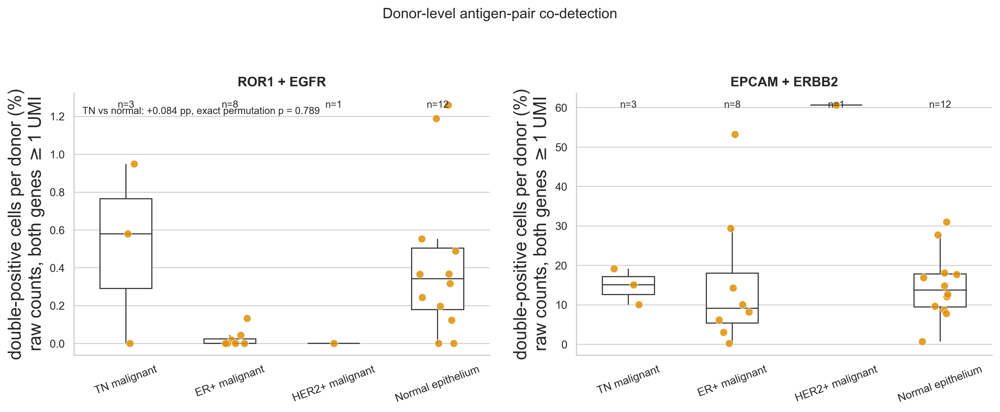

In [126]:
group_order = ["TN malignant", "ER+ malignant", "HER2+ malignant", "Normal epithelium"]

fig, axes = plt.subplots(1, len(antigen_pairs), figsize=(13, 5.2), sharey=False)

for ax, (gene_a, gene_b) in zip(np.atleast_1d(axes), antigen_pairs):

    pair = f"{gene_a}+{gene_b}"
    block = donor_levels[(donor_levels["pair"] == pair) & (donor_levels["min_umi"] == primary_min_umi)]
    present = [g for g in group_order if g in set(block["group"])]

    sns.boxplot(data=block, x="group", y="prevalence", order=present, ax=ax,
                showfliers=False, width=0.5, boxprops={"facecolor": "white"}, showcaps=False)
    sns.stripplot(data=block, x="group", y="prevalence", order=present, ax=ax,
                  size=7, alpha=0.85, jitter=0.18, linewidth=0.5, edgecolor="white")

    for position, group in enumerate(present):
        donors = block.loc[block["group"] == group]
        ax.text(position, ax.get_ylim()[1] * 0.97, f"n={len(donors)}",
                ha="center", va="top", fontsize=9)

    ax.set_title(f"{gene_a} + {gene_b}", fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(f"double-positive cells per donor (%)\nraw counts, both genes $\\geq${primary_min_umi} UMI")
    ax.tick_params(axis="x", rotation=20)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].annotate(
    f"TN vs normal: {donor_inference['difference_pp']:+.3f} pp, "
    f"exact permutation p = {donor_inference['exact_permutation_p']:.3f}",
    xy=(0.02, 0.92), xycoords="axes fraction", fontsize=9,
)

fig.suptitle("Donor-level antigen-pair co-detection", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(fig_dir / "fig2b_donor_level_codetection.png", dpi=300, bbox_inches="tight")
plt.show()

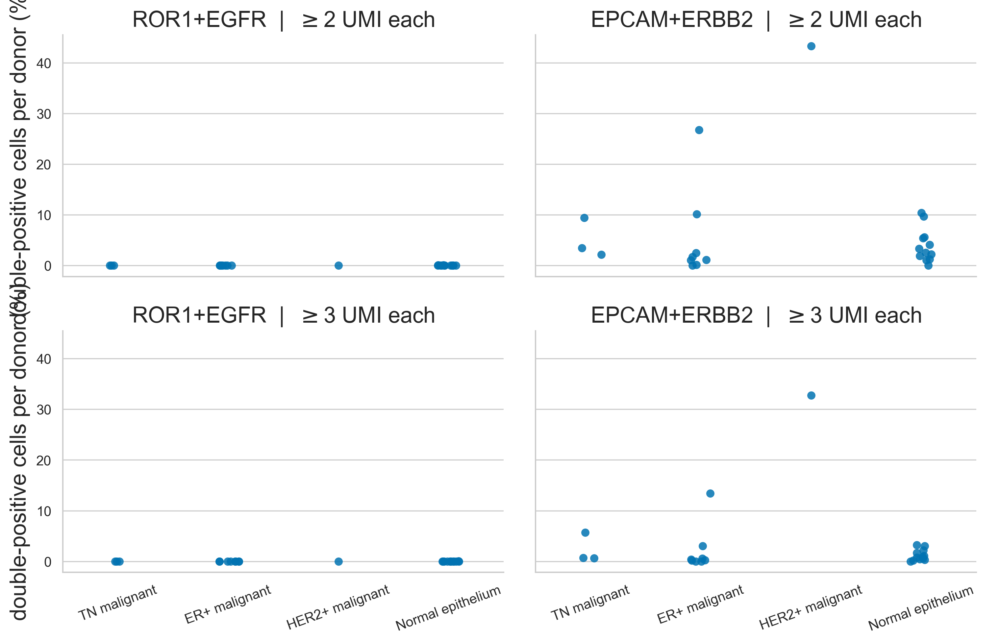

In [127]:
# the stricter thresholds belong in the supplement, not the main panel
supplementary = donor_levels[donor_levels["min_umi"] > primary_min_umi]

g = sns.catplot(data=supplementary, x="group", y="prevalence", col="pair", row="min_umi",
                order=[g for g in group_order if g in set(supplementary["group"])],
                kind="strip", height=3.4, aspect=1.5, size=6, alpha=0.85)

g.set_axis_labels("", "double-positive cells per donor (%)")
g.set_titles("{col_name}  |  $\\geq${row_name} UMI each")

for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=20)

g.figure.savefig(fig_dir / "fig2b_supplement_umi_thresholds.png", dpi=300, bbox_inches="tight")
plt.show()

### Does the malignancy threshold decide the result?



Malignancy is called at the 95th percentile of the normal-condition CNV score, which is an operational choice. The table below recomputes co-detection prevalence at three quantiles so the reader can see whether the subtype contrast depends on it.

In [128]:
cnv_score = epi.obs["cnv_score"].to_numpy(dtype=float)
normal_scores = cnv_score[(epi.obs["condition"].astype(str) == "N").to_numpy()]

rows = []

for quantile in [0.90, 0.95, 0.99]:

    threshold = float(np.quantile(normal_scores, quantile))

    for gene_a, gene_b in antigen_pairs:

        positive = (raw_counts(epi, gene_a) >= primary_min_umi) & (raw_counts(epi, gene_b) >= primary_min_umi)

        for condition in ["TN", "ER+", "HER2+"]:

            called = (epi.obs["condition"].astype(str) == condition).to_numpy() & (cnv_score >= threshold)

            rows.append({
                "pair": f"{gene_a}+{gene_b}",
                "normal_quantile": quantile,
                "cnv_threshold": threshold,
                "condition": condition,
                "n_called_malignant": int(called.sum()),
                "n_double_positive": int((called & positive).sum()),
                "prevalence_pct": 100 * (called & positive).sum() / called.sum() if called.sum() else np.nan,
            })

cnv_sensitivity = pd.DataFrame(rows)
cnv_sensitivity.to_csv(df_dir / "coexpression_cnv_threshold_sensitivity.csv", index=False)

cnv_sensitivity.pivot_table(index=["pair", "normal_quantile"], columns="condition",
                            values="prevalence_pct").round(4)

condition                        ER+    HER2+       TN
pair        normal_quantile                           
EPCAM+ERBB2 0.90             13.3275  64.4719  15.0011
            0.95             15.5605  64.6146  14.9106
            0.99             23.1306  60.5312  15.1173
ROR1+EGFR   0.90              0.0129   0.0000   1.1176
            0.95              0.0135   0.0000   1.1654
            0.99              0.0162   0.0000   1.1949

### normal signal 



Normal double positives are recurrent across donors, so it matters which normal
epithelial cells carry them. The clustering annotation leaves most normal cells in a
generic epithelial category, so lineage is assigned here from canonical markers.

In [129]:
# the signatures already used for epithelial annotation in 002, unchanged
normal_lineage_markers = {
    "Basal": ["KRT14", "KRT5", "KRT17", "TP63", "MYLK", "OXTR"],
    "Luminal progenitor": ["ALDH1A3", "KIT", "ELF5", "SLPI", "LTF", "KRT15"],
    "Mature luminal": ["ESR1", "PGR", "FOXA1", "ANKRD30A", "AREG", "TFF1", "GATA3"],
}

# an alternative set, used only to check the assignment is not signature-specific
alternative_lineage_markers = {
    "Basal": ["KRT5", "KRT14", "KRT17", "TP63", "ACTA2", "MYLK", "OXTR", "MYH11", "CNN1"],
    "Luminal progenitor": ["KIT", "ALDH1A3", "ELF5", "SLPI", "LTF", "KRT23", "CD14", "PROM1"],
    "Mature luminal": ["ESR1", "PGR", "FOXA1", "ANKRD30A", "AGR2", "TFF1", "TFF3"],
}

In [130]:
normal = epi[(epi.obs["condition"].astype(str) == "N")].copy()
normal.X = normal.layers["lognorm"]

In [131]:
for lineage, markers in normal_lineage_markers.items():

    present = [g for g in markers if g in normal.var_names]
    sc.tl.score_genes(normal, present, score_name=lineage, random_state=0)

In [132]:
lineage_scores = normal.obs[list(normal_lineage_markers)]

# argmax of three module scores. This is a phenotype label, not a calibrated classification, so it is reported as "-like" and cross-checked against the independent cluster annotation from 002 below.
normal_lineage = lineage_scores.idxmax(axis=1).where(lineage_scores.max(axis=1) > 0, "Unassigned")

In [133]:
normal_double_positive = pd.Series(
    (raw_counts(normal, "ROR1") >= primary_min_umi)
    & (raw_counts(normal, "EGFR") >= primary_min_umi),
    index=normal.obs_names,
)

# concordance with the existing cluster annotation rather than independent validation: both come from this dataset, and the 002 annotation was itself built on overlapping epithelial markers
lineage_agreement = pd.crosstab(
    normal_lineage.loc[normal_double_positive],
    normal.obs.loc[normal_double_positive, "cl_annotation"].astype(str),
)

lineage_agreement

cl_annotation,Epithelial,Epithelial: Basal,Epithelial: Cycling,Epithelial: Luminal Progenitor
row_0,,,,
Basal,0,14,0,9
Luminal progenitor,3,0,0,74
Mature luminal,1,0,0,5
Unassigned,2,0,1,4


In [134]:
# does the phenotype label depend on which signature was used?
for lineage, markers in alternative_lineage_markers.items():

    present = [g for g in markers if g in normal.var_names]
    sc.tl.score_genes(normal, present, score_name=f"alt {lineage}", random_state=0)

In [135]:
alternative_scores = normal.obs[[f"alt {k}" for k in alternative_lineage_markers]]
alternative_scores.columns = list(alternative_lineage_markers)

alternative_lineage = alternative_scores.idxmax(axis=1).where(
    alternative_scores.max(axis=1) > 0, "Unassigned"
)

signature_sensitivity = pd.crosstab(
    normal_lineage.loc[normal_double_positive],
    alternative_lineage.loc[normal_double_positive],
)

signature_sensitivity

col_0,Basal,Luminal progenitor,Mature luminal,Unassigned
row_0,,,,
Basal,16,7,0,0
Luminal progenitor,2,75,0,0
Mature luminal,0,2,4,0
Unassigned,0,6,0,1


In [136]:
normal_window = pd.DataFrame({
    "lineage": normal_lineage.to_numpy(),
    "patient": normal.obs["patient"].astype(str).to_numpy(),
    "ror1": raw_counts(normal, "ROR1") >= primary_min_umi,
    "egfr": raw_counts(normal, "EGFR") >= primary_min_umi,
})

normal_window["double_positive"] = normal_window["ror1"] & normal_window["egfr"]

In [137]:
decomposition = normal_window.groupby("lineage", observed=True).agg(
    cells=("double_positive", "size"),
    n_ror1=("ror1", "sum"),
    n_egfr=("egfr", "sum"),
    n_double_positive=("double_positive", "sum"),
)

decomposition["pct_of_normal"] = decomposition["cells"] / decomposition["cells"].sum() * 100
decomposition["ror1_pct"] = decomposition["n_ror1"] / decomposition["cells"] * 100
decomposition["egfr_pct"] = decomposition["n_egfr"] / decomposition["cells"] * 100
decomposition["double_positive_pct"] = decomposition["n_double_positive"] / decomposition["cells"] * 100
decomposition["pct_of_double_positive"] = (
    decomposition["n_double_positive"] / decomposition["n_double_positive"].sum() * 100
)
decomposition["enrichment"] = decomposition["pct_of_double_positive"] / decomposition["pct_of_normal"]

decomposition.to_csv(df_dir / "coexpression_normal_decomposition.csv")

In [138]:
decomposition.round(3)

,cells,n_ror1,n_egfr,n_double_positive,pct_of_normal,ror1_pct,egfr_pct,double_positive_pct,pct_of_double_positive,enrichment
lineage,,,,,,,,,,
Basal,9464,64,2199,23,36.851,0.676,23.235,0.243,20.354,0.552
Luminal progenitor,7515,113,3300,77,29.262,1.504,43.912,1.025,68.142,2.329
Mature luminal,6478,18,627,6,25.224,0.278,9.679,0.093,5.310,0.211
Unassigned,2225,18,453,7,8.664,0.809,20.360,0.315,6.195,0.715


In [139]:
# is the dominant lineage the same donor to donor, or one donor's quirk?
per_donor_lineage = (
    normal_window[normal_window["double_positive"]]
    .groupby(["patient", "lineage"], observed=True)
    .size()
    .unstack(fill_value=0)
)

dominant_lineage = decomposition["pct_of_double_positive"].idxmax()

f"{dominant_lineage} leads in {int((per_donor_lineage.idxmax(axis=1) == dominant_lineage).sum())} of {len(per_donor_lineage)} donors"

'Luminal progenitor leads in 7 of 10 donors'

In [140]:
per_donor_lineage

lineage,Basal,Luminal progenitor,Mature luminal,Unassigned
patient,,,,
N-MH0023,2,5,1,0
N-MH0169,2,2,0,0
N-MH275,0,2,0,0
N-PM0019,3,5,3,3
N-PM0092,5,3,0,2
N-PM0095,2,25,0,1
N-PM0230,0,0,1,0
N-PM0233,4,6,0,0
N-PM0342,2,12,1,1


In [141]:
# epi contains only singlets, so counting doublets here is uninformative. The measurement that matters was made in 001, before removal: how enriched the double positives were among cells scDblFinder called doublets.
qc = pd.concat(
    [pd.read_csv(path) for path in sorted(df_dir.glob("qc_*.csv"))],
    ignore_index=True,
)

In [142]:
scored = qc[qc["ror1_egfr_dp"] > 0].copy()
scored["enrichment"] = scored["ror1_egfr_dp_doublet_pct"] / scored["pct_doublets"]

doublet_audit = scored.groupby("condition", observed=True).agg(
    samples=("sample", "size"),
    double_positive_cells=("ror1_egfr_dp", "sum"),
    doublet_pct_among_dp=("ror1_egfr_dp_doublet_pct", "median"),
    background_doublet_pct=("pct_doublets", "median"),
    enrichment=("enrichment", "median"),
)

doublet_audit.to_csv(df_dir / "coexpression_doublet_audit.csv")
doublet_audit.round(2)

,samples,double_positive_cells,doublet_pct_among_dp,background_doublet_pct,enrichment
condition,,,,,
ER,10,66,0.0,7.35,0.00
HER2,5,11,0.0,8.90,0.00
N,12,489,21.3,7.20,2.63
TN,8,332,19.9,8.50,1.45


In [143]:
# everything the freeze gate asks for, in one output. Structural invariants are asserted; the data-dependent counts are printed so a real change is visible rather than silently blocked.
assert primary_min_umi == 1
assert len(permuted) == comb(len(pooled), n_tn)
assert normal_double_positive.sum() == int(
    decomposition["n_double_positive"].sum()
)

gate = {
    "primary_min_umi": int(primary_min_umi),
    "double_positive_by_group": therapeutic_window.set_index("group")["total_double_positive"].to_dict(),
    "donors_by_group": therapeutic_window.set_index("group")["donors"].to_dict(),
    "normal_double_positive": int(normal_double_positive.sum()),
    "n_permutations": int(len(permuted)),
    "exact_permutation_p": donor_inference["exact_permutation_p"],
    "bootstrap_ci_pp": donor_inference["bootstrap_ci_pp"],
    "rarefaction_iterations": int(n_rarefactions),
    "rarefaction_cells": int(fixed_cell_mask.sum()),
    "rarefaction_prevalences_finite": bool(depth_sensitivity[["tn_median", "normal_median"]].notna().all().all()),
    "rarefaction_undefined_ratios": depth_sensitivity.set_index("depth")["undefined_ratio"].to_dict(),
}

gate

{'primary_min_umi': 1,
 'double_positive_by_group': {'ER+ malignant': 9,
  'HER2+ malignant': 0,
  'Normal epithelium': 113,
  'TN malignant': 145},
 'donors_by_group': {'ER+ malignant': 8,
  'HER2+ malignant': 1,
  'Normal epithelium': 12,
  'TN malignant': 3},
 'normal_double_positive': 113,
 'n_permutations': 455,
 'exact_permutation_p': 0.789010989010989,
 'bootstrap_ci_pp': [-0.4137745918117982, 0.5518436985515067],
 'rarefaction_iterations': 100,
 'rarefaction_cells': 69201,
 'rarefaction_prevalences_finite': True,
 'rarefaction_undefined_ratios': {1000: 33.0, 2000: 0.0, 3000: 0.0}}

In [144]:
# doublet control measured per sample in 001, before doublet removal
qc_path = metadata_dir / "qc_summary.csv"

In [145]:
if qc_path.exists():

    qc = pd.read_csv(qc_path)

    columns = [c for c in ["sample", "condition", "epcam_erbb2_dp",
                           "epcam_erbb2_dp_doublet_pct", "pct_doublets"]
               if c in qc.columns]

    print(qc[columns])

    if {"epcam_erbb2_dp_doublet_pct", "pct_doublets"}.issubset(qc.columns):
        print(
            f"\nmedian doublet rate among EPCAM+ERBB2+ cells: "
            f"{qc['epcam_erbb2_dp_doublet_pct'].median():.1f}% "
            f"against {qc['pct_doublets'].median():.1f}% background"
        )

else:
    print(f"{rel(qc_path)} not found; run 001 to regenerate it")

                       sample condition  epcam_erbb2_dp  \
0        GSM4909295_ER-AH0319        ER             264   
1        GSM4909296_ER-MH0001        ER              22   
2        GSM4909297_ER-MH0125        ER             357   
3        GSM4909298_ER-PM0360        ER             218   
4     GSM4909299_ER-MH0114-T3        ER            1304   
5        GSM4909300_ER-MH0032        ER              97   
6        GSM4909301_ER-MH0042        ER              99   
7        GSM4909302_ER-MH0025        ER             385   
8        GSM4909303_ER-MH0151        ER             350   
9        GSM4909304_ER-MH0163        ER             371   
10    GSM4909305_ER-MH0029-7C        ER             391   
11    GSM4909306_ER-MH0029-9C        ER             522   
12       GSM4909307_ER-MH0040        ER             346   
13     GSM4909309_ER-MH0043-T        ER             416   
14     GSM4909311_ER-MH0056-T        ER              14   
15     GSM4909313_ER-MH0064-T        ER             245 

#  condition and programme composition of the double-positive cells

In [146]:
hallmark_order = list(epi.uns["gavish_hallmark_order"])

In [147]:
hallmark_palette = dict(zip(hallmark_order, epi.uns["gavish_hallmark_colors"]))

In [148]:
# cells with no programme identity are stacked as their own grey classes, so that a bar's height equals the number of co-expressing cells
non_programme = ["not_scored", "non_malignant"]

In [149]:
hallmark_palette["not_scored"] = "#CCCCCC"
hallmark_palette["non_malignant"] = "#E6E6E6"

In [150]:
# the dominant relative programme class from the Gavish notebook: a descriptive winner over every scored malignant cell, not a gated identity call
state_key = "Gavish_dominant_class"

In [151]:
observed_states = set(epi.obs[state_key].astype(str))

In [152]:
states = [s for s in hallmark_order + non_programme if s in observed_states]

In [153]:
condition_palette = {
    "TN": "#976391",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "N": "#031A6B",
}

In [154]:
panel_conditions = ["TN", "ER+", "HER2+", "N"]

In [155]:
def coexpression_composition(double_positive, scope_mask=None, conditions=None):
    # per condition: total co-expressing cells, their programme classes, and the percentage of that condition which co-expresses
    counts = {}
    totals = {}
    percentages = {}

    if scope_mask is None:
        scope_mask = np.ones(epi.n_obs, bool)

    if conditions is None:
        conditions = panel_conditions

    state_values = epi.obs[state_key].astype(str).to_numpy()
    condition_values = epi.obs["condition"].astype(str).to_numpy()

    for condition in conditions:

        condition_mask = (condition_values == condition) & scope_mask
        both = condition_mask & double_positive

        totals[condition] = int(both.sum())
        percentages[condition] = 100 * both.sum() / condition_mask.sum()
        counts[condition] = {s: int((both & (state_values == s)).sum()) for s in states}

    return counts, totals, percentages

In [156]:
def draw_coexpression_figure(min_umi, filename, scope="all epithelial"):
    """scope is "all epithelial" or "malignant only"; normal tissue contains no
    malignant cells, so it is dropped from the malignant-only panels."""
    scope_mask = np.ones(epi.n_obs, bool) if scope == "all epithelial" else malignant_only

    # normal tissue has no malignant cells, so it has no denominator in that scope
    conditions_in_scope = (
        panel_conditions if scope == "all epithelial" else [c for c in panel_conditions if c != "N"]
    )

    exported = []

    panels = {
        f"{a} + {b}": np.asarray(coexpression_group(epi, a, b, min_umi) == "Double positive")
        for a, b in antigen_pairs
    }

    fig = plt.figure(figsize=(27, 8))
    outer = gridspec.GridSpec(1, 2, figure=fig, wspace=0.22)

    for column, (title, double_positive) in enumerate(panels.items()):

        inner = gridspec.GridSpecFromSubplotSpec(
            1, 2, subplot_spec=outer[column], width_ratios=[4.5, 1.5], wspace=0.06
        )

        ax_bar = fig.add_subplot(inner[0])
        ax_dot = fig.add_subplot(inner[1])

        counts, totals, percentages = coexpression_composition(double_positive, scope_mask, conditions_in_scope)

        for condition in conditions_in_scope:
            exported.append({
                "pair": title, "scope": scope, "min_umi": min_umi, "condition": condition,
                "n_double_positive": totals[condition],
                "n_cells_in_scope": int(((epi.obs["condition"].astype(str) == condition).to_numpy() & scope_mask).sum()),
                "pct_of_condition": percentages[condition],
                **{f"n_{s}": counts[condition][s] for s in states},
            })

        x = np.arange(len(conditions_in_scope))
        bottom = np.zeros(len(conditions_in_scope))

        for state in states:

            values = np.array([counts[c][state] for c in conditions_in_scope])

            ax_bar.bar(x, values, bottom=bottom, width=0.6,
                       color=hallmark_palette.get(state, "lightgrey"), zorder=3)

            bottom += values

        assert np.allclose(bottom, [totals[c] for c in conditions_in_scope])

        headroom = max(totals.values()) if max(totals.values()) > 0 else 1

        for i, condition in enumerate(conditions_in_scope):
            if totals[condition] > 0:
                ax_bar.text(i, totals[condition] + headroom * 0.02, f"{totals[condition]:,}",
                            ha="center", va="bottom", fontsize=18, fontweight="bold")

        ax_bar.set_xticks(x)
        ax_bar.set_xticklabels(conditions_in_scope, fontsize=20)
        ax_bar.set_ylabel("co-expressing cells", fontsize=20)
        ax_bar.set_ylim(0, headroom * 1.18)
        ax_bar.tick_params(axis="y", labelsize=20)
        ax_bar.set_title(title, loc="left", fontsize=20, fontweight="bold")
        ax_bar.grid(axis="y", color="lightgrey")
        ax_bar.spines[["top", "right"]].set_visible(False)

        for i, condition in enumerate(conditions_in_scope):
            ax_dot.scatter(percentages[condition], i, color=condition_palette[condition], s=80)
            ax_dot.plot([0, percentages[condition]], [i, i],
                        color=condition_palette[condition], alpha=0.4)
            ax_dot.text(percentages[condition] * 1.05 + 0.05, i,
                        f"{percentages[condition]:.2f}%", fontsize=18, va="center")

        max_pct = max(percentages.values())

        ax_dot.set_xlim(0, max_pct * 1.6 if max_pct > 0 else 1)
        ax_dot.set_yticks(range(len(conditions_in_scope)))
        ax_dot.set_yticklabels(conditions_in_scope, fontsize=20)
        ax_dot.invert_yaxis()
        ax_dot.set_xlabel("% of condition", fontsize=20)
        ax_dot.tick_params(axis="x", labelsize=18)
        ax_dot.grid(axis="x", color="lightgrey")
        ax_dot.spines[["top", "right", "left"]].set_visible(False)

    fig.legend(
        handles=[mpatches.Patch(color=hallmark_palette.get(s, "lightgrey"), label=s) for s in states],
        title="Dominant programme class", loc="lower center", bbox_to_anchor=(0.5, -0.12),
        ncol=4, frameon=False,
    )

    fig.legend(
        handles=[mpatches.Patch(color=condition_palette[c], label=c) for c in conditions_in_scope],
        title="Condition", loc="upper right", frameon=False,
    )

    plt.suptitle(
        f"Antigen-pair co-expression, raw counts at >= {min_umi} UMI\n"
        "bars: number of co-expressing cells; dots: percentage of the condition",
        fontsize=14, fontweight="bold", y=1.03,
    )

    plt.savefig(fig_dir / filename, dpi=300, bbox_inches="tight")
    plt.show()

    return pd.DataFrame(exported)


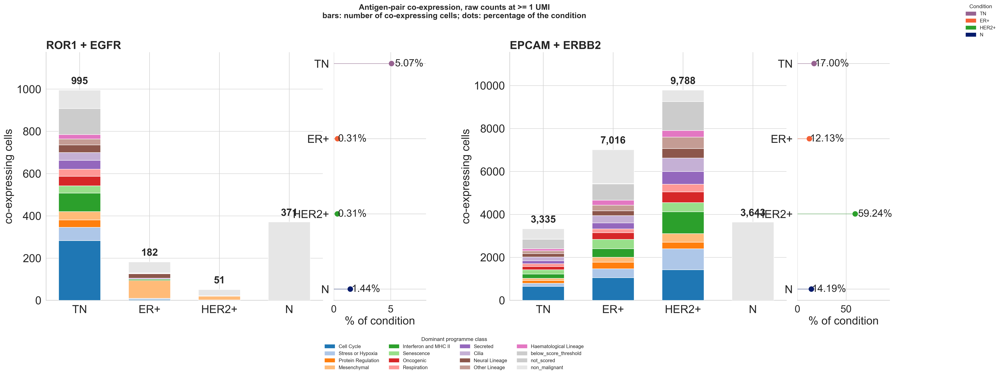

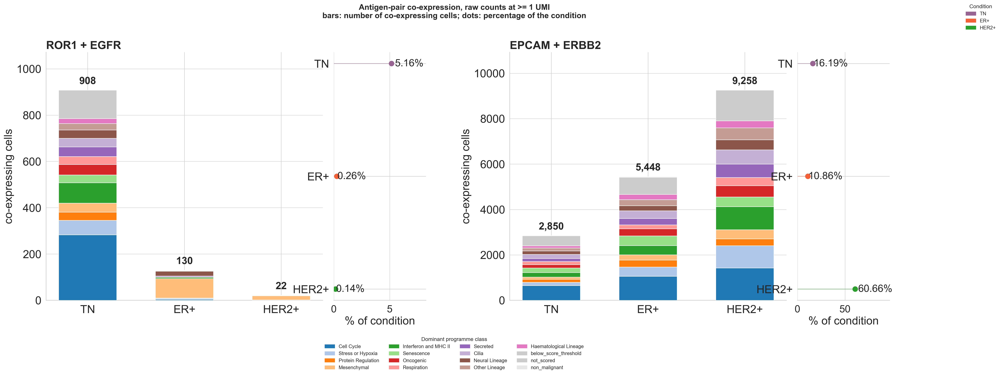

In [157]:
panel_frames = []

for scope in ["all epithelial", "malignant only"]:
    panel_frames.append(
        draw_coexpression_figure(primary_min_umi, f"coexpression_composition_{scope.replace(' ', '_')}.png", scope)
    )

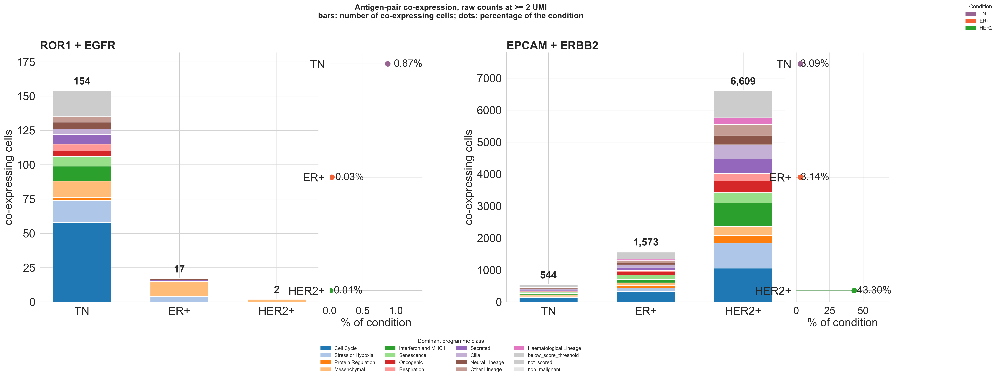

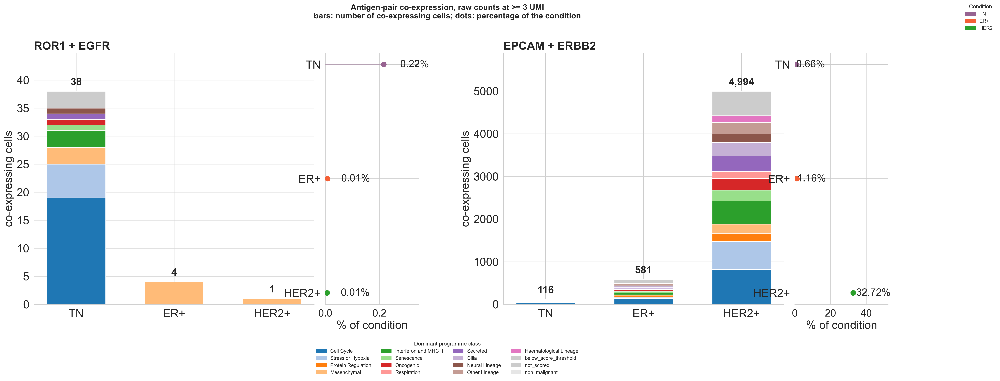

In [158]:
# thresholds above the primary definition, as sensitivity
for threshold in min_umi_sweep:
    if threshold == primary_min_umi:
        continue
    panel_frames.append(
        draw_coexpression_figure(threshold, f"coexpression_composition_min_umi_{threshold}.png", "malignant only")
    )

coexpression_panel_values = pd.concat(panel_frames, ignore_index=True)
coexpression_panel_values.to_csv(df_dir / "coexpression_panel_values.csv", index=False)

In [159]:
coexpression_panel_values

,pair,scope,min_umi,condition,n_double_positive,n_cells_in_scope,pct_of_condition,n_Cell Cycle,n_Stress or Hypoxia,n_Protein Regulation,...,n_Oncogenic,n_Respiration,n_Secreted,n_Cilia,n_Neural Lineage,n_Other Lineage,n_Haematological Lineage,n_below_score_threshold,n_not_scored,n_non_malignant
0,ROR1 + EGFR,all epithelial,1,TN,995,19615,5.072648,283,63,35,...,45,34,42,37,36,28,21,123,0,87
1,ROR1 + EGFR,all epithelial,1,ER+,182,57852,0.314596,4,5,1,...,1,0,4,0,21,2,0,2,0,52
2,ROR1 + EGFR,all epithelial,1,HER2+,51,16524,0.308642,1,1,0,...,0,0,0,0,1,0,0,0,0,29
3,ROR1 + EGFR,all epithelial,1,N,371,25682,1.444592,0,0,0,...,0,0,0,0,0,0,0,0,0,371
4,EPCAM + ERBB2,all epithelial,1,TN,3335,19615,17.002294,652,143,133,...,149,134,137,177,152,133,94,441,7,485
5,EPCAM + ERBB2,all epithelial,1,ER+,7016,57852,12.127498,1059,410,306,...,312,176,283,333,225,266,230,756,28,1568
6,EPCAM + ERBB2,all epithelial,1,HER2+,9788,16524,59.235052,1429,976,306,...,498,361,591,628,442,529,306,1352,0,530
7,EPCAM + ERBB2,all epithelial,1,N,3643,25682,14.185032,0,0,0,...,0,0,0,0,0,0,0,0,0,3643
8,ROR1 + EGFR,malignant only,1,TN,908,17606,5.157333,283,63,35,...,45,34,42,37,36,28,21,123,0,0
9,ROR1 + EGFR,malignant only,1,ER+,130,50158,0.259181,4,5,1,...,1,0,4,0,21,2,0,2,0,0


### Is the cell-cycle plurality an enrichment?

Cell Cycle being the largest class among double positives is a statement about their composition, not about enrichment. The primary population-level comparison below is restricted to TN malignant cells and pairs each donor's double-positive cells with the remaining programme-scored malignant cells from that donor. A secondary CMH analysis estimates the cell-level association conditional on the observed donors; it is reported separately because cells do not replace donors as biological replicates.

In [160]:
# eligibility threshold chosen for this analysis, not preregistered. The sweep below shows how many donors remain eligible at other choices.
min_double_positive_cells = 5

In [161]:
double_positive = np.asarray(
    coexpression_group(epi, "ROR1", "EGFR", primary_min_umi) == "Double positive"
)

tn_malignant = malignant_only & (epi.obs["condition"].astype(str) == "TN").to_numpy()

In [162]:
state_values = epi.obs[state_key].astype(str).to_numpy()

# a cell without a programme assignment cannot contribute to a programme fraction, so the comparison population is scored malignant cells, not all malignant cells
programme_scored = ~np.isin(state_values, ["non_malignant", "not_scored"])

tn_scored_malignant = (
    malignant_only
    & (epi.obs["condition"].astype(str) == "TN").to_numpy()
    & programme_scored
)

rows = []

for donor in np.unique(patient_values[tn_scored_malignant]):

    in_donor = tn_scored_malignant & (patient_values == donor)

    positive = in_donor & double_positive
    remainder = in_donor & ~double_positive

    # computed for every donor; the eligibility rule is applied per analysis below
    rows.append({
        "donor": donor,
        "n_double_positive": int(positive.sum()),
        "n_other_malignant": int(remainder.sum()),
        "cell_cycle_in_double_positive": (
            100 * (state_values[positive] == "Cell Cycle").mean() if positive.sum() else np.nan
        ),
        "cell_cycle_in_other": (
            100 * (state_values[remainder] == "Cell Cycle").mean() if remainder.sum() else np.nan
        ),
    })

cell_cycle_by_donor = pd.DataFrame(rows)
cell_cycle_by_donor["difference_pp"] = (
    cell_cycle_by_donor["cell_cycle_in_double_positive"] - cell_cycle_by_donor["cell_cycle_in_other"]
)
cell_cycle_by_donor["eligible"] = cell_cycle_by_donor["n_double_positive"] >= min_double_positive_cells

cell_cycle_by_donor.to_csv(df_dir / "coexpression_cell_cycle_by_donor.csv", index=False)

In [163]:
cell_cycle_by_donor.round(1)

,donor,n_double_positive,n_other_malignant,cell_cycle_in_double_positive,cell_cycle_in_other,difference_pp,eligible
0,TN,192,5461,13.5,9.9,3.7,True
1,TN-B1,716,11091,35.9,18.2,17.7,True
2,TN-MH0114,0,106,NaN,15.1,NaN,False


In [164]:
# a zero paired difference carries no directional information, so the sign test is taken over the donors whose difference is non-zero
paired = cell_cycle_by_donor.loc[cell_cycle_by_donor["eligible"], "difference_pp"].dropna().to_numpy()
nonzero = paired[paired != 0]

cell_cycle_enrichment = {
    "donors_examined": int(len(cell_cycle_by_donor)),
    "min_double_positive_cells": int(min_double_positive_cells),
    "eligible_donors": int(len(paired)),
    "donors_positive": int((paired > 0).sum()),
    "donors_negative": int((paired < 0).sum()),
    "donors_tied": int((paired == 0).sum()),
    "sign_test_denominator": int(len(nonzero)),
    "median_difference_pp": float(np.median(paired)) if len(paired) else np.nan,
    "sign_test_p": float(binomtest(int((nonzero > 0).sum()), len(nonzero)).pvalue) if len(nonzero) else np.nan,
    "smallest_attainable_p": float(binomtest(len(nonzero), len(nonzero)).pvalue) if len(nonzero) else np.nan,
}

epi.uns["coexpression_cell_cycle"] = cell_cycle_enrichment

In [165]:
cell_cycle_enrichment

{'donors_examined': 3,
 'min_double_positive_cells': 5,
 'eligible_donors': 2,
 'donors_positive': 2,
 'donors_negative': 0,
 'donors_tied': 0,
 'sign_test_denominator': 2,
 'median_difference_pp': 10.694456534773028,
 'sign_test_p': 0.5,
 'smallest_attainable_p': 0.5}

In [166]:
# how much does the eligibility threshold decide the answer?
rows = []

for threshold in [1, 5, 10, 20]:

    difference = cell_cycle_by_donor.loc[
        cell_cycle_by_donor["n_double_positive"] >= threshold, "difference_pp"
    ].dropna()

    nonzero = difference[difference != 0]

    rows.append({
        "min_double_positive_cells": threshold,
        "eligible_donors": len(difference),
        "donors_positive": int((difference > 0).sum()),
        "donors_negative": int((difference < 0).sum()),
        "donors_tied": int((difference == 0).sum()),
        "sign_test_denominator": len(nonzero),
        "median_difference_pp": difference.median() if len(difference) else np.nan,
        "sign_test_p": binomtest(int((nonzero > 0).sum()), len(nonzero)).pvalue if len(nonzero) else np.nan,
        "smallest_attainable_p": binomtest(len(nonzero), len(nonzero)).pvalue if len(nonzero) else np.nan,
    })

eligibility_sweep = pd.DataFrame(rows)
eligibility_sweep.to_csv(df_dir / "coexpression_cell_cycle_eligibility_sweep.csv", index=False)

eligibility_sweep.round(3)

,min_double_positive_cells,eligible_donors,donors_positive,donors_negative,donors_tied,sign_test_denominator,median_difference_pp,sign_test_p,smallest_attainable_p
0,1,2,2,0,0,2,10.694,0.5,0.5
1,5,2,2,0,0,2,10.694,0.5,0.5
2,10,2,2,0,0,2,10.694,0.5,0.5
3,20,2,2,0,0,2,10.694,0.5,0.5


### Conditional cell-level programme association

The donor sign test above is the primary test of generalisation across tumours. The CMH analysis below asks a narrower question: within the observed eligible TN tumours, are double-positive cells more likely than the remaining malignant cells to carry each relative dominant programme class? It stratifies by donor and corrects across all 13 programme classes. Because the observations are cells, this is conditional evidence within this cohort rather than a substitute for donor-level replication. Library-depth stratification is reported as a sensitivity analysis because low-count co-detection is depth dependent.

In [167]:
sample_values = epi.obs["sample"].astype(str).to_numpy()
patient_values = epi.obs["patient"].astype(str).to_numpy()
eligible_programme_donors = set(
    cell_cycle_by_donor.loc[cell_cycle_by_donor["eligible"], "donor"].astype(str)
)
cell_gate_label = epi.uns["gavish_assignment"]["cell_gate_label"]  # "below_score_threshold"

programmes = sorted(
    p for p in np.unique(state_values[tn_scored_malignant]) if p != cell_gate_label
)

programme_rows = []

for programme in programmes:
    tables = []

    for donor in sorted(eligible_programme_donors):
        in_donor = tn_scored_malignant & (patient_values == donor)
        positive = in_donor & double_positive
        remainder = in_donor & ~double_positive

        table = np.array([
            [int((state_values[positive] == programme).sum()),
             int((state_values[positive] != programme).sum())],
            [int((state_values[remainder] == programme).sum()),
             int((state_values[remainder] != programme).sum())],
        ])

        assert table.sum(axis=1).min() > 0
        tables.append(table)

    fit = StratifiedTable(np.dstack(tables))
    ci_low, ci_high = fit.oddsratio_pooled_confint()

    programme_rows.append({
        "programme": programme,
        "eligible_donors": len(tables),
        "min_double_positive_cells": min_double_positive_cells,
        "common_odds_ratio": float(fit.oddsratio_pooled),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "p_cmh": float(fit.test_null_odds().pvalue),
    })

programme_cmh = pd.DataFrame(programme_rows).sort_values("p_cmh").reset_index(drop=True)
assert len(programme_cmh) == len(programmes) == 13
programme_cmh["p_holm"] = multipletests(programme_cmh["p_cmh"], method="holm")[1]
programme_cmh.to_csv(df_dir / "coexpression_programme_cmh.csv", index=False)
programme_cmh.round(4)

,programme,eligible_donors,min_double_positive_cells,common_odds_ratio,ci_low,ci_high,p_cmh,p_holm
0,Cell Cycle,2,5,2.3357,2.0132,2.7098,0.0000,0.0000
1,Other Lineage,2,5,0.4328,0.2959,0.6331,0.0000,0.0001
2,Cilia,2,5,0.5814,0.4160,0.8125,0.0013,0.0144
3,Haematological Lineage,2,5,0.5101,0.3289,0.7910,0.0022,0.0216
4,Interferon and MHC II,2,5,1.4129,1.1252,1.7742,0.0027,0.0247
5,Senescence,2,5,0.6039,0.4260,0.8561,0.0042,0.0337
6,Stress or Hypoxia,2,5,1.3153,1.0087,1.7150,0.0425,0.2976
7,Respiration,2,5,0.7297,0.5142,1.0355,0.0765,0.4588
8,Neural Lineage,2,5,0.7468,0.5312,1.0500,0.0921,0.4605
9,Mesenchymal,2,5,1.1224,0.8058,1.5633,0.4952,1.0000


In [168]:
# Non-parametric depth adjustment: split cells into library-size quantiles within each technical sample, then stratify jointly by patient, sample and depth bin. This preserves the biological donor key without mixing libraries.
depth_frame = pd.DataFrame({
    "patient": patient_values[tn_scored_malignant],
    "sample": sample_values[tn_scored_malignant],
    "double_positive": double_positive[tn_scored_malignant],
    "cell_cycle": state_values[tn_scored_malignant] == "Cell Cycle",
    "log_library_size": np.log1p(
        epi.obs["total_counts"].to_numpy()[tn_scored_malignant]
    ),
})
depth_frame = depth_frame[depth_frame["patient"].isin(eligible_programme_donors)].copy()

depth_rows = []

for n_bins in [5, 10, 20]:
    tables = []

    for (patient, sample), donor_frame in depth_frame.groupby(["patient", "sample"], observed=True):
        donor_frame = donor_frame.copy()
        donor_frame["depth_bin"] = pd.qcut(
            donor_frame["log_library_size"], q=n_bins, labels=False, duplicates="drop"
        )

        for _, block in donor_frame.groupby("depth_bin", observed=True):
            if block["double_positive"].nunique() < 2 or block["cell_cycle"].nunique() < 2:
                continue

            table = (pd.crosstab(block["double_positive"], block["cell_cycle"])
                     .reindex(index=[True, False], columns=[True, False], fill_value=0)
                     .to_numpy())
            tables.append(table)

    fit = StratifiedTable(np.dstack(tables))
    ci_low, ci_high = fit.oddsratio_pooled_confint()

    depth_rows.append({
        "depth_bins_per_donor": n_bins,
        "informative_strata": len(tables),
        "eligible_donors": len(eligible_programme_donors),
        "common_odds_ratio": float(fit.oddsratio_pooled),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "p_cmh": float(fit.test_null_odds().pvalue),
    })

cell_cycle_depth_sensitivity = pd.DataFrame(depth_rows)
cell_cycle_depth_sensitivity.to_csv(
    df_dir / "coexpression_cell_cycle_depth_sensitivity.csv", index=False
)

cell_cycle_row = programme_cmh.loc[programme_cmh["programme"] == "Cell Cycle"].iloc[0]
epi.uns["coexpression_cell_cycle"].update({
    "conditional_cell_level_cmh_or": float(cell_cycle_row["common_odds_ratio"]),
    "conditional_cell_level_cmh_ci": [float(cell_cycle_row["ci_low"]), float(cell_cycle_row["ci_high"])],
    "conditional_cell_level_cmh_p": float(cell_cycle_row["p_cmh"]),
    "conditional_cell_level_cmh_holm_p": float(cell_cycle_row["p_holm"]),
    "depth_sensitivity": {
        str(int(row["depth_bins_per_donor"])): {
            key: (int(value) if key in ["informative_strata", "eligible_donors"] else float(value))
            for key, value in row.items() if key != "depth_bins_per_donor"
        }
        for row in depth_rows
    },
})

cell_cycle_row.to_frame().T.round(4), cell_cycle_depth_sensitivity.round(4)

(    programme eligible_donors min_double_positive_cells common_odds_ratio  \
 0  Cell Cycle               2                         5          2.335655   
 
      ci_low   ci_high p_cmh p_holm  
 0  2.013203  2.709755   0.0    0.0  ,
    depth_bins_per_donor  informative_strata  eligible_donors  \
 0                     5                  19                2   
 1                    10                  34                2   
 2                    20                  61                2   
 
    common_odds_ratio  ci_low  ci_high   p_cmh  
 0             1.4200  1.1983   1.6826  0.0000  
 1             1.3728  1.1568   1.6292  0.0002  
 2             1.3620  1.1469   1.6174  0.0004  )

In [169]:
# per-sample prevalence among malignant cells. One point per sample, so a subtype effect can be told apart from one dominant tumour.
malignant = epi.obs["malignant"].to_numpy()

frames = []

for gene_a, gene_b in antigen_pairs:

    dp = np.asarray(coexpression_group(epi, gene_a, gene_b, primary_min_umi) == "Double positive")

    frame = pd.DataFrame({
        "sample": epi.obs["sample"].astype(str).to_numpy(),
        "condition": epi.obs["condition"].astype(str).to_numpy(),
        "dp": dp,
    })[malignant]

    counts = (frame.groupby(["condition", "sample"], observed=True)["dp"]
              .agg(["size", "sum"]).rename(columns={"size": "cells", "sum": "n_dp"}))

    counts = counts[counts["cells"] >= 100].reset_index()
    counts["pct"] = 100 * counts["n_dp"] / counts["cells"]
    counts["pair"] = f"{gene_a}-{gene_b}"

    frames.append(counts)

per_sample_prevalence = pd.concat(frames, ignore_index=True)
per_sample_prevalence.to_csv(df_dir / "coexpression_prevalence_per_sample.csv", index=False)

In [170]:
for pair, block in sorted(per_sample_prevalence.groupby("pair"), key=lambda kv: kv[0] != "ROR1-EGFR"):
    hit = block.groupby("condition", observed=True)["n_dp"].apply(lambda s: f"{(s > 0).sum()}/{len(s)}")
    print(pair, dict(hit))

ROR1-EGFR {'ER+': '5/17', 'HER2+': '1/6', 'TN': '5/7'}
EPCAM-ERBB2 {'ER+': '17/17', 'HER2+': '6/6', 'TN': '7/7'}


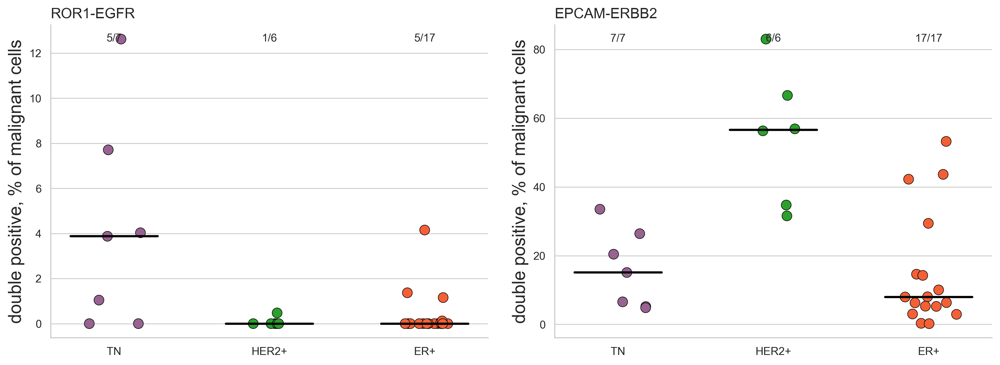

In [171]:
# ROR1-EGFR first, to match the ordering of Figure 2b
pair_order = [f"{a}-{b}" for a, b in antigen_pairs]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (pair, block) in zip(axes, [(p, per_sample_prevalence[per_sample_prevalence["pair"] == p])
           for p in pair_order]):

    present = [c for c in tumour_conditions if c in set(block["condition"])]

    sns.stripplot(data=block, x="condition", y="pct", order=present, hue="condition",
                  hue_order=present, palette=condition_palette_supp, legend=False,
                  size=9, jitter=0.18, edgecolor="black", linewidth=0.5, ax=ax)

    for i, condition in enumerate(present):
        median = block.loc[block["condition"] == condition, "pct"].median()
        ax.plot([i - 0.28, i + 0.28], [median, median], color="black", linewidth=2, zorder=5)

    for i, condition in enumerate(present):
        block_c = block[block["condition"] == condition]
        ax.text(i, ax.get_ylim()[1] * 0.97, f"{(block_c['n_dp'] > 0).sum()}/{len(block_c)}",
                ha="center", va="top", fontsize=10)

    ax.set_title(pair, loc="left", fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("double positive, % of malignant cells")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(fig_dir / "coexpression_prevalence_per_sample.png", dpi=300, bbox_inches="tight")
plt.show()

In [172]:
# programme enrichment: how the double positives are distributed across dominant programme classes, against all scored malignant cells the dominant class is ungated, so only these two are ever excluded
unassigned = ["non_malignant", "not_scored"]

scored = ~epi.obs[state_key].astype(str).isin(unassigned)

dp_ror1_egfr = np.asarray(coexpression_group(epi, "ROR1", "EGFR", primary_min_umi) == "Double positive")

observed_state = epi.obs[state_key].astype(str)

background = observed_state[scored].value_counts(normalize=True) * 100
double_pos = observed_state[scored & dp_ror1_egfr].value_counts(normalize=True) * 100

programme_enrichment = pd.DataFrame({
    "all_malignant_pct": background.round(2),
    "double_positive_pct": double_pos.round(2),
    "n_double_positive": observed_state[scored & dp_ror1_egfr].value_counts(),
}).dropna(subset=["double_positive_pct"])

programme_enrichment["enrichment"] = (programme_enrichment["double_positive_pct"]
                                      / programme_enrichment["all_malignant_pct"]).round(2)

programme_enrichment = programme_enrichment.sort_values("enrichment", ascending=False)
programme_enrichment.to_csv(df_dir / "programme_enrichment_double_positive.csv")
programme_enrichment

,all_malignant_pct,double_positive_pct,n_double_positive,enrichment
Gavish_dominant_class,,,,
Mesenchymal,5.26,13.30,141,2.53
Cell Cycle,15.68,27.17,288,1.73
Interferon and MHC II,7.39,8.96,95,1.21
Neural Lineage,5.58,5.47,58,0.98
Stress or Hypoxia,6.62,6.51,69,0.98
Secreted,5.00,4.34,46,0.87
Oncogenic,5.05,4.34,46,0.86
Protein Regulation,3.96,3.40,36,0.86
below_score_threshold,17.26,11.79,125,0.68


In [173]:
plot_data = programme_enrichment[programme_enrichment["n_double_positive"] > 0].copy()
plot_data["log2_enrichment"] = np.log2(plot_data["enrichment"])

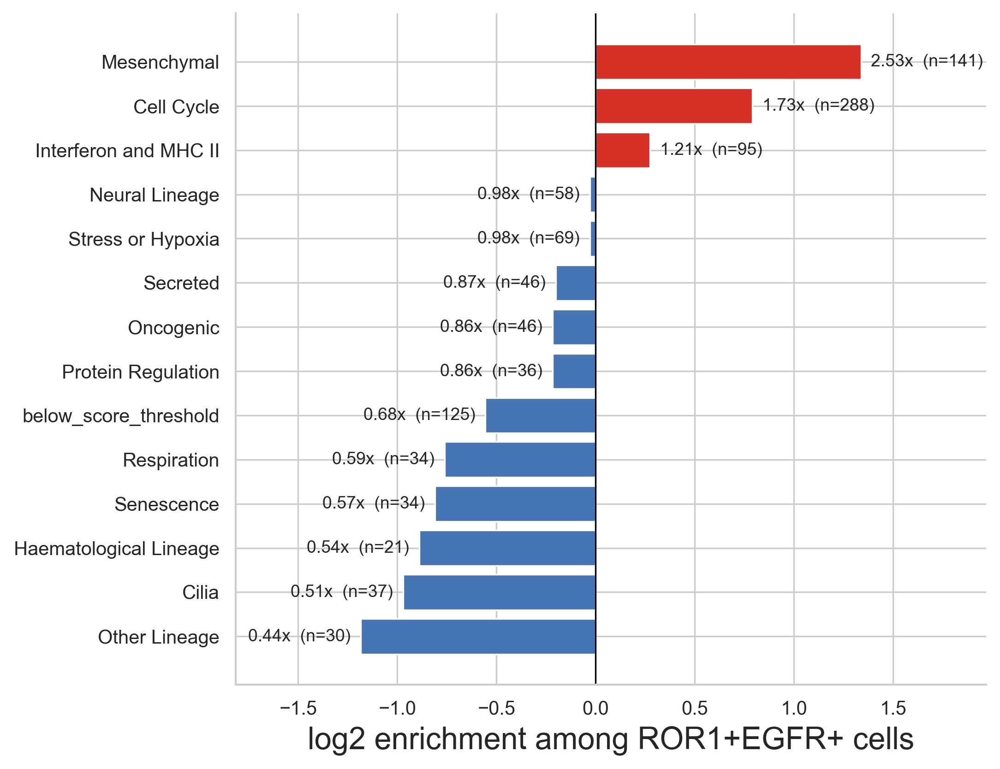

In [174]:
fig, ax = plt.subplots(figsize=(7, max(3, 0.45 * len(plot_data))))

ax.barh(plot_data.index, plot_data["log2_enrichment"],
        color=["#D73027" if v > 0 else "#4575B4" for v in plot_data["log2_enrichment"]])

for i, (label, row) in enumerate(plot_data.iterrows()):
    offset = 0.05 if row["log2_enrichment"] >= 0 else -0.05
    ax.text(row["log2_enrichment"] + offset, i, f"{row['enrichment']:.2f}x  (n={int(row['n_double_positive'])})",
            va="center", ha="left" if row["log2_enrichment"] >= 0 else "right", fontsize=9)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("log2 enrichment among ROR1+EGFR+ cells")
ax.set_ylabel("")
ax.invert_yaxis()
ax.margins(x=0.25)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig(fig_dir / "programme_enrichment_double_positive.png", dpi=300, bbox_inches="tight")
plt.show()

In [175]:
# how concentrated the double positives are across samples
for gene_a, gene_b in antigen_pairs:

    column = f"{gene_a}_{gene_b}_group"

    per_sample = (
        epi.obs
        .assign(double_positive=epi.obs[column].eq("Double positive"))
        .groupby(["sample", "condition"], observed=True)
        .agg(n_cells=("double_positive", "size"), n_double_positive=("double_positive", "sum"))
        .reset_index()
    )

    per_sample = per_sample[per_sample["n_double_positive"] > 0].sort_values(
        "n_double_positive", ascending=False
    )

    print(f"\n{gene_a}-{gene_b}: {len(per_sample)} of {epi.obs['sample'].nunique()} samples")

    for n in [1, 5, 10, 20]:
        print(f"  samples with >= {n:2d}: {int((per_sample['n_double_positive'] >= n).sum())}")

    print(per_sample.head(10))

    per_sample.to_csv(df_dir / f"{gene_a}_{gene_b}_double_positive_per_sample.csv", index=False)


ROR1-EGFR: 27 of 44 samples
  samples with >=  1: 27
  samples with >=  5: 24
  samples with >= 10: 20
  samples with >= 20: 14
                       sample condition  n_cells  n_double_positive
16    GSM4909285_TN-B1-MH4031        TN     4707                533
18   GSM4909287_TN-B1-Tum0554        TN     2866                226
13       GSM4909282_TN-MH0135        TN     5000                190
8   GSM4909270_N-PM0342-Total         N     4361                110
30    GSM4909299_ER-MH0114-T3       ER+     5000                100
2   GSM4909257_N-PM0095-Total         N     2221                 52
11  GSM4909276_N-PM0372-Total         N     1683                 51
7   GSM4909268_N-MH0023-Total         N     4071                 48
43     GSM4909317_ER-MH0173-T       ER+     2625                 40
19    GSM4909288_TN-B1-MH0177        TN      883                 36

EPCAM-ERBB2: 44 of 44 samples
  samples with >=  1: 44
  samples with >=  5: 44
  samples with >= 10: 42
  samples with >=

## Background comparison

Where the two pairs sit against randomly sampled detectable gene pairs, drawn
repeatedly so that the reported percentile does not depend on one seed.

In [176]:
counts_matrix = epi.layers["counts"].tocsr()

In [177]:
condition_values = epi.obs["condition"].astype(str).to_numpy()

In [178]:
detection_rate = np.asarray((counts_matrix > 0).mean(axis=0)).ravel()

In [179]:
# genes drawn from a broad detection band; this is a detectable-gene null, not a curated surfaceome, and is labelled as such
band = np.flatnonzero((detection_rate >= 0.001) & (detection_rate <= 0.30))

In [180]:
target_index = {g: int(np.flatnonzero(epi.var_names == g)[0]) for g in target_genes}

In [181]:
reported_pairs = [
    ("ROR1", "EGFR"), ("EPCAM", "ERBB2"), ("ROR1", "EPCAM"),
    ("ROR1", "ERBB2"), ("EGFR", "ERBB2"), ("EGFR", "EPCAM"),
]

In [182]:
len(band)

17441

In [183]:
def background_draw(seed):

    rng = np.random.default_rng(seed)

    pick = np.unique(np.concatenate([
        rng.choice(band, 300, replace=False),
        list(target_index.values()),
    ]))

    names = epi.var_names[pick]

    def co_detection(mask):
        binary = (counts_matrix[mask][:, pick] > 0).astype(np.float32).toarray()
        return (binary.T @ binary) / binary.shape[0], binary.shape[0]

    co_tn, n_tn = co_detection(condition_values == "TN")
    co_er, n_er = co_detection(condition_values == "ER+")

    upper = np.triu_indices(len(pick), k=1)

    # the pseudocount keeps pairs absent from ER+ finite
    ratio = (co_tn[upper] + 1 / n_tn) / (co_er[upper] + 1 / n_er)

    position = {g: int(np.flatnonzero(names == g)[0]) for g in target_index}

    rows = []

    for gene_a, gene_b in reported_pairs:

        i, j = sorted([position[gene_a], position[gene_b]])
        k = int(np.flatnonzero((upper[0] == i) & (upper[1] == j))[0])

        rows.append({
            "seed": seed,
            "pair": f"{gene_a}-{gene_b}",
            "tn_over_er": ratio[k],
            "percentile": 100 * (ratio < ratio[k]).mean(),
        })

    return pd.DataFrame(rows), ratio

In [184]:
background_frames = []

In [185]:
last_ratio = None

In [186]:
for seed in range(20):
    frame, last_ratio = background_draw(seed)
    background_frames.append(frame)

In [187]:
background = pd.concat(background_frames, ignore_index=True)

In [188]:
background_summary = (
    background
    .groupby("pair")
    .agg(median_tn_over_er=("tn_over_er", "median"),
         median_percentile=("percentile", "median"),
         min_percentile=("percentile", "min"),
         max_percentile=("percentile", "max"))
    .sort_values("median_percentile", ascending=False)
)

In [189]:
background_summary.round(2)

,median_tn_over_er,median_percentile,min_percentile,max_percentile
pair,,,,
ROR1-EPCAM,30.969999,97.90,96.48,99.13
ROR1-EGFR,28.180000,97.63,96.09,98.92
ROR1-ERBB2,10.490000,92.32,89.37,93.34
EGFR-EPCAM,5.730000,83.95,79.57,85.70
EGFR-ERBB2,3.070000,70.57,65.93,74.92
EPCAM-ERBB2,1.400000,37.21,34.18,41.89


In [190]:
background.to_csv(df_dir / "antigen_pair_background_draws.csv", index=False)

In [191]:
background_summary.to_csv(df_dir / "antigen_pair_background_summary.csv")

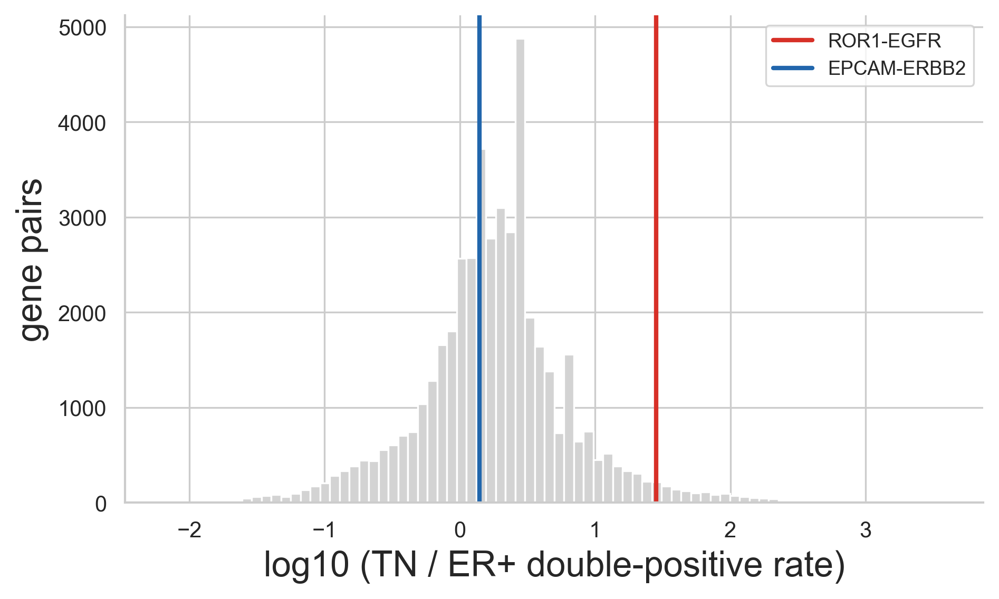

In [192]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(np.log10(last_ratio), bins=80, color="lightgrey")

for pair, color in [("ROR1-EGFR", "#D73027"), ("EPCAM-ERBB2", "#2166AC")]:
    value = background_summary.loc[pair, "median_tn_over_er"]
    ax.axvline(np.log10(value), color=color, linewidth=2, label=pair)

ax.set_xlabel("log10 (TN / ER+ double-positive rate)")
ax.set_ylabel("gene pairs")
ax.legend()
sns.despine()

plt.savefig(fig_dir / "antigen_pair_background.png", dpi=300, bbox_inches="tight")
plt.show()

## Mesenchymal programme activity and ROR1



This secondary analysis compares ROR1-positive with ROR1-negative malignant cells,
not ROR1–EGFR double-positive with other cells. Too few independent donors contain
enough double-positive cells for a powered donor-level mesenchymal analysis. Patients
represented in more than one tumour condition are excluded from the pan-tumour
comparison so that no patient contributes to both groups.

In [193]:
group_palette = {
    "Double negative": "#BDBDBD",
    "EGFR only": "#4C72B0",
    "ROR1 only": "#DD8452",
    "Double positive": "#55A868",
}

In [194]:
group_order = list(epi.obs["ROR1_EGFR_group"].cat.categories)

In [195]:
assert not set(group_order) - set(group_palette)

In [196]:
group_order

['Double negative', 'ROR1 only', 'EGFR only', 'Double positive']

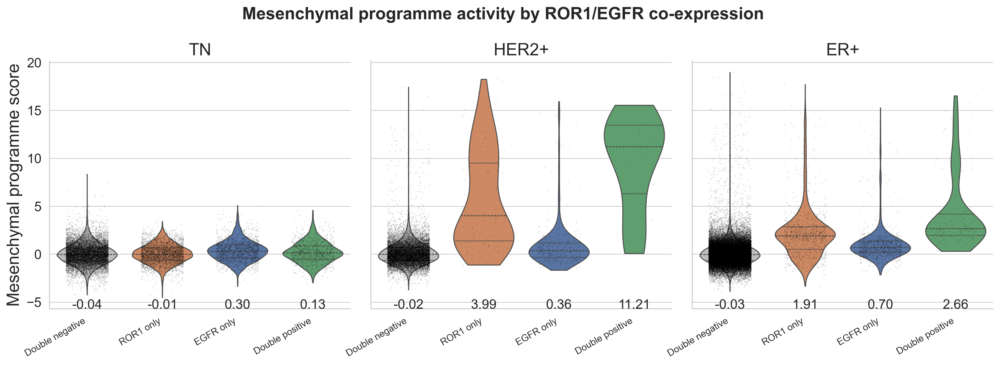

In [197]:
g = sns.catplot(
    data=epi.obs,
    x="ROR1_EGFR_group",
    y="Gavish_Mesenchymal_score",
    hue="ROR1_EGFR_group",
    col="condition",
    col_order=tumour_conditions,
    order=group_order,
    hue_order=group_order,
    kind="violin",
    inner="quartile",
    palette=group_palette,
    legend=False,
    cut=0,
    height=5,
    aspect=1,
)

for ax, condition in zip(g.axes.flat, tumour_conditions):

    subset = epi.obs[epi.obs["condition"].astype(str) == condition]

    sns.stripplot(data=subset, x="ROR1_EGFR_group", y="Gavish_Mesenchymal_score",
                  order=group_order, ax=ax, color="black", size=1.2, alpha=0.15, jitter=0.28)

    for i, group in enumerate(group_order):

        median = subset.loc[subset["ROR1_EGFR_group"] == group, "Gavish_Mesenchymal_score"].median()

        if not np.isnan(median):
            ax.text(i, ax.get_ylim()[0] + 0.01, f"{median:.2f}", ha="center", fontsize=14)

    ax.axhline(0, color="grey", linewidth=0.6, linestyle="--", zorder=0)
    ax.tick_params(axis="y", labelsize=14)

g.set_titles("{col_name}", size=18)
g.set_axis_labels("", "Mesenchymal programme score", fontsize=18)
g.set_xticklabels(rotation=30, ha="right")

plt.suptitle("Mesenchymal programme activity by ROR1/EGFR co-expression",
             fontsize=18, fontweight="bold", y=1.05)

plt.savefig(fig_dir / "mesenchymal_score_by_coexpression.png", dpi=300, bbox_inches="tight")
plt.show()

In [198]:
# Cochran-Mantel-Haenszel, stratified by patient. Patients represented in more than one tumour condition are excluded from this exploratory pan-tumour test so that each biological replicate contributes to only one condition.
malignant = epi.obs["malignant"].to_numpy() & epi.obs["condition"].astype(str).ne("N").to_numpy()

In [199]:
ror1_positive = raw_counts(epi, "ROR1") >= primary_min_umi

In [200]:
frame = pd.DataFrame({
    "patient": epi.obs["patient"].astype(str).to_numpy(),
    "condition": epi.obs["condition"].astype(str).to_numpy(),
    "sample": epi.obs["sample"].astype(str).to_numpy(),
    "ror1": np.where(ror1_positive, "ROR1_pos", "ROR1_neg"),
    "mesenchymal": epi.obs[state_key].astype(str).eq("Mesenchymal").to_numpy(),
    "mesenchymal_score": epi.obs["Gavish_Mesenchymal_score"].to_numpy(),
}, index=epi.obs_names)[malignant]

patient_condition_counts = frame[["patient", "condition"]].drop_duplicates().groupby(
    "patient", observed=True
)["condition"].nunique()
cross_condition_patients = set(patient_condition_counts[patient_condition_counts > 1].index)
if cross_condition_patients:
    print("excluding patients spanning tumour conditions:", sorted(cross_condition_patients))
    frame = frame[~frame["patient"].isin(cross_condition_patients)].copy()

In [201]:
len(frame), frame["patient"].nunique()

(83027, 12)

In [202]:
(frame["ror1"] == "ROR1_pos").sum()

np.int64(655)

In [203]:
tables = []

In [204]:
for patient, group in frame.groupby("patient", observed=True):

    table = np.array([
        [int(((group["ror1"] == "ROR1_pos") & group["mesenchymal"]).sum()),
         int(((group["ror1"] == "ROR1_pos") & ~group["mesenchymal"]).sum())],
        [int(((group["ror1"] == "ROR1_neg") & group["mesenchymal"]).sum()),
         int(((group["ror1"] == "ROR1_neg") & ~group["mesenchymal"]).sum())],
    ])

    if table.sum(axis=1).min() > 0:
        tables.append(table)

In [205]:
if not tables:
    print("no patient contains both ROR1+ and ROR1- malignant cells")

else:
    stratified = StratifiedTable(np.dstack(tables))
    low, high = stratified.oddsratio_pooled_confint()

    print(f"strata: {len(tables)} patients, {sum(t.sum() for t in tables):,} cells")
    print(f"CMH odds ratio, mesenchymal class among ROR1+ vs ROR1-: "
          f"{stratified.oddsratio_pooled:.2f} (95% CI {low:.2f}-{high:.2f})")
    print(f"  p = {stratified.test_null_odds().pvalue:.4g}")
    print(f"  homogeneity p = {stratified.test_equal_odds().pvalue:.4g}")

strata: 11 patients, 80,761 cells
CMH odds ratio, mesenchymal class among ROR1+ vs ROR1-: 1.26 (95% CI 0.89-1.79)
  p = 0.2034
  homogeneity p = 1.187e-05


In [206]:
# paired comparison of the continuous score, one value per patient per group
n_positive = frame[frame["ror1"] == "ROR1_pos"].groupby("patient", observed=True).size()

In [207]:
eligible = n_positive[n_positive >= 20].index

In [208]:
mesenchymal_by_donor = (
    frame[frame["patient"].isin(eligible)]
    .groupby(["patient", "ror1"], observed=True)["mesenchymal_score"]
    .median()
    .unstack()
    .dropna()
)

In [209]:
len(mesenchymal_by_donor)

3

In [210]:
if len(mesenchymal_by_donor) < 3:
    print("too few patients for a paired test")

else:
    statistic, p_value = wilcoxon(mesenchymal_by_donor["ROR1_pos"], mesenchymal_by_donor["ROR1_neg"])

    print(f"paired Wilcoxon p = {p_value:.4g}")
    print(f"median difference = "
          f"{(mesenchymal_by_donor['ROR1_pos'] - mesenchymal_by_donor['ROR1_neg']).median():+.4f}")

paired Wilcoxon p = 0.25
median difference = +0.0675


In [211]:
mesenchymal_by_donor.round(4)

ror1,ROR1_neg,ROR1_pos
patient,,
ER,-0.0001,0.3839
TN,-0.0021,0.0574
TN-B1,-0.0015,0.0660


In [212]:
mesenchymal_by_donor.to_csv(df_dir / "mesenchymal_score_ror1_per_donor.csv")

## Stemness

`MALTA_CURATED_STEMNESS_MARKERS` (MSigDB C2:CGP, systematic name M30411;
Malta et al. 2018), a literature-curated marker collection scored with
`scanpy.tl.score_genes`. This is an exploratory analysis separate from the
Gavish programme classes. Inference uses the same TN-only, programme-scored
and at-least-five-double-positive-cell donor set as the primary cell-cycle analysis.

In [213]:
stemness_genes = [
    "NES", "KDM5B", "ZFP42", "CTNNB1", "ZSCAN4", "EPAS1", "EZH2", "HIF1A",
    "MYC", "NOTCH1", "POU5F1", "BMI1", "SOX2", "TWIST1", "NANOG", "LGR5",
    "PROM1", "KLF4", "ABCG2", "CD34", "CD44",
]

In [214]:
present = [g for g in stemness_genes if g in epi.var_names]

In [215]:
len(present), len(stemness_genes)

(21, 21)

In [216]:
[g for g in stemness_genes if g not in epi.var_names]

[]

In [217]:
sc.tl.score_genes(
    epi,
    gene_list=present,
    score_name="stemness_score",
    layer="lognorm",
    use_raw=False,
    random_state=0,
)

In [218]:
epi.obs["stemness_score"].describe().round(4)

count    119673.0000
mean          0.0478
std           0.1000
min          -0.1876
25%          -0.0324
50%           0.0382
75%           0.1055
max           0.7622
Name: stemness_score, dtype: float64

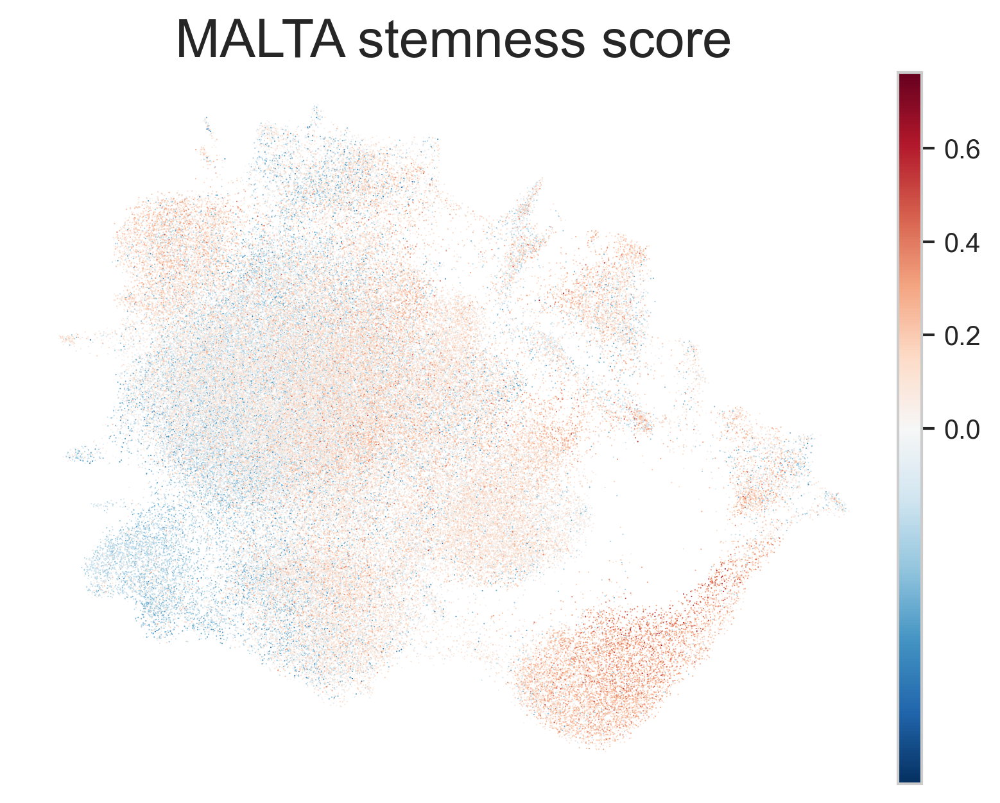

In [219]:
sc.pl.umap(epi, color="stemness_score", frameon=False, cmap="RdBu_r", vcenter=0,
           title="MALTA stemness score", show=False)

plt.savefig(fig_dir / "stemness_score_umap.png", dpi=300, bbox_inches="tight")
plt.show()

In [220]:
# Apply the same TN, programme-scored and >=5-DP donor eligibility used by the primary programme comparison. Stemness is a separate exploratory score.
stemness = epi.obs.loc[tn_scored_malignant].copy()
stemness["double_positive"] = double_positive[tn_scored_malignant]
stemness = stemness[stemness["patient"].astype(str).isin(eligible_programme_donors)].copy()

In [221]:
stemness_by_donor = (
    stemness
    .groupby(["patient", "double_positive"], observed=True)["stemness_score"]
    .median()
    .unstack()
    .dropna()
)

In [222]:
len(stemness_by_donor)

2

In [223]:
counts = stemness.groupby(["patient", "double_positive"], observed=True).size().unstack()
print(counts)
print("patients with both groups present:", counts.notna().all(axis=1).sum())
print("double_positive value counts overall:", stemness["double_positive"].value_counts())

double_positive  False  True 
patient                      
TN                5461    192
TN-B1            11091    716
patients with both groups present: 2
double_positive value counts overall: double_positive
False    16552
True       908
Name: count, dtype: int64


In [224]:
stemness_difference = stemness_by_donor[True] - stemness_by_donor[False]
assert len(stemness_difference) >= 3
stemness_nonzero = stemness_difference[stemness_difference != 0]

stemness_test = {
    "eligible_donors": int(len(stemness_difference)),
    "donors_positive": int((stemness_difference > 0).sum()),
    "median_difference": float(stemness_difference.median()),
    "wilcoxon_p": float(wilcoxon(stemness_difference).pvalue),
    "sign_test_p": float(binomtest(
        int((stemness_nonzero > 0).sum()), len(stemness_nonzero)
    ).pvalue),
}
stemness_test

AssertionError: 

In [ ]:
stemness_by_donor.to_csv(df_dir / "stemness_score_tn_by_donor.csv")

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 5))

for donor, row in stemness_by_donor.iterrows():
    ax.plot([0, 1], [row[False], row[True]], color="0.65", linewidth=1, zorder=1)
    ax.scatter([0, 1], [row[False], row[True]], s=55, zorder=2)

ax.set_xticks([0, 1], ["other malignant", "ROR1+EGFR+"])
ax.set_ylabel("median MALTA stemness score per donor")
ax.set_title("TN donors with >=5 double-positive cells")
ax.spines[["top", "right"]].set_visible(False)
ax.text(0.02, 0.98,
        f"paired Wilcoxon p = {stemness_test['wilcoxon_p']:.3f}",
        transform=ax.transAxes, va="top", fontsize=9)

fig.tight_layout()
fig.savefig(fig_dir / "stemness_score_tn_paired.png", dpi=300, bbox_inches="tight")
plt.show()

## Save

In [ ]:
final_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}

In [ ]:
assert final_positive == baseline_positive

In [ ]:
out_path = save_dir / "epithelial_antigen_coexpression.h5ad"

In [ ]:
tmp_path = out_path.with_suffix(".h5ad.tmp")

In [ ]:
epi.write_h5ad(tmp_path, compression="gzip")

In [ ]:
os.replace(tmp_path, out_path)

In [ ]:
out_path.name

In [ ]:
epi

In [ ]:
check = sc.read_h5ad(out_path, backed="r")

In [ ]:
assert check.n_obs == epi.n_obs

In [ ]:
assert check.n_vars == epi.n_vars

In [ ]:
del check

In [ ]:
gc.collect()

In [ ]:
from importlib.metadata import PackageNotFoundError, version
import platform
import sys


In [ ]:
import session_info

In [ ]:
session_info.show()